# AA-HybridUNet vs. EfficientNet-B4 U-Net — Artifact-Aware Pneumothorax Segmentation (one-file pipeline)

**Research prototype — not a clinically validated diagnostic device.** Everything below is measured by this notebook;
no number is typed by hand.

**How to run (Kaggle):** attach the dataset *Chest X-Ray Images with Pneumothorax Masks* (vbookshelf), set **Accelerator = GPU T4**,
**Internet = ON** (needed once to download the ImageNet weights), then **Run All** — or **Save Version → Save & Run All**.
Nothing else needs to be uploaded: the whole code base is written out by the cells in section 1.

| Section | What happens |
|---|---|
| 0 | Settings, environment and GPU diagnostics |
| 1 | The code base is written to `/kaggle/working/aa_pneumo_experiment/src` and imported (also reusable for the Streamlit app) |
| 2 | Experiment definitions and **empty** result tables |
| 3 | Dataset audit on **every** file, class distribution, split, 512-px cache |
| 4 | Visual checks: images/masks, synthetic-artifact gallery |
| 5 | Model tests, GPU memory probe, measured speed, smoke tests |
| 6 | **Training** (10 epochs per run, resumable; by default only the proposed model and the baseline are trained, see `ONLY_MAIN_MODELS`) |
| 7 | Validation: threshold/post-processing tuning, clean and artifact-corrupted validation |
| 8 | **Final test evaluation** (only place the official test split is read) |
| 9 | Efficiency, tables (CSV/Markdown/LaTeX), figures |
| 10 | Export: deployment bundle for Streamlit + results package |

**Why this replaces your previous notebook:** the per-image soft-Dice loss could not decrease on the ~78 % empty images (training loss stuck at ~1.15,
the model predicted nothing), the validation Dice counted empty-vs-empty as 1.0 (so 0.64 was mostly negatives), the run did not use the proposed
artifact head/gates, and there was no augmentation, baseline, threshold tuning or test evaluation. All fixed below.

**Time budget.** The notebook measures the real speed of your GPU in section 5 and prints a projected time per run before training starts.
Training stops cleanly before Kaggle's 12-hour limit; to continue, *Save Version*, then in the next session add the previous version's **Output**
as an input (`+ Add Input → Notebook Output`) and Run All again — finished runs are skipped and unfinished runs resume from their last epoch.

## 0. Settings and diagnostics

In [1]:
# ============================== USER SETTINGS (edit here) ==============================
import os, sys, time, json, shutil, random, warnings, hashlib, platform
from pathlib import Path
warnings.filterwarnings("ignore")
SESSION_T0 = time.time()
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # reduces GPU memory fragmentation (must be set before torch initialises CUDA)

TINY = os.environ.get("AA_TINY") == "1"       # developer test mode used to test this notebook on a CPU. Leave unset on Kaggle.

IMG_SIZE        = 512      # network input size (multiple of 32)
EPOCHS          = 10       # epochs per run (reduced from 20)
EFFECTIVE_BS    = 8        # images per optimizer step (micro-batch is probed automatically; gradient accumulation fills the rest)
NEG_FRAC        = 0.5      # every epoch uses ALL lesion images + this fraction of the negatives (new random subset each epoch)
SEED            = 42
VAL_FRAC        = 0.10     # fraction of the official TRAIN split used for validation
ONLY_MAIN_MODELS = True   # True = train ONLY the proposed model (aa_artifact) and the baseline (baseline_std); False = also aa_std + ablations
RUN_ABLATIONS   = True     # tier-2 runs (ablations + control). Tier-1 (baseline, AA-std, AA-artifact) always run first.
SESSION_BUDGET_HOURS = 11.0   # Kaggle kills a session at 12 h
EVAL_RESERVE_HOURS   = 1.6    # time kept free at the end for validation analysis + test evaluation + export
FORCE_REEVAL    = False    # True = recompute validation/test results even if they exist on disk
DATASET_ROOT    = None     # None = auto-detect a folder with png_images/ and png_masks/ under /kaggle/input
PRETRAINED      = True     # ImageNet-pretrained EfficientNet-B4 (needs Internet ON for the first download)
LIMIT_FILES     = None     # debugging only: cache just the first N files

ON_KAGGLE = Path("/kaggle/working").exists()
WORK = Path(os.environ.get("AA_WORK") or ("/kaggle/working/aa_pneumo_experiment" if ON_KAGGLE else "./aa_pneumo_experiment"))
CACHE_DIR = Path("/kaggle/temp/aa_cache") if Path("/kaggle/temp").exists() else WORK / "cache"
WORKERS = min(4, os.cpu_count() or 2)
if TINY:
    IMG_SIZE, EPOCHS, EFFECTIVE_BS, PRETRAINED, WORKERS, NEG_FRAC = 64, 2, 4, False, 2, 1.0
    DATASET_ROOT = os.environ["AA_FAKE_ROOT"]; SESSION_BUDGET_HOURS = 100; VAL_FRAC = 0.2
assert IMG_SIZE % 32 == 0
AREA_SCALE = (IMG_SIZE / 512.0) ** 2          # pixel-area thresholds below are defined at 512 px and scaled for other sizes

RUNS_DIR, RES_DIR = WORK / "runs", WORK / "results"
VAL_DIR, TEST_DIR, TABLES_DIR, FIG_DIR = RES_DIR / "val", RES_DIR / "test", RES_DIR / "tables", RES_DIR / "figures"
for d in (WORK, RUNS_DIR, VAL_DIR, TEST_DIR, TABLES_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
DEADLINE = SESSION_T0 + (SESSION_BUDGET_HOURS - EVAL_RESERVE_HOURS) * 3600
print("work dir :", WORK, "\ncache dir:", CACHE_DIR)

work dir : /kaggle/working/aa_pneumo_experiment 
cache dir: /kaggle/working/aa_pneumo_experiment/cache


In [2]:
# ============================== environment + GPU diagnostics ==============================
import numpy as np, pandas as pd, torch
try:
    import timm
except ImportError:
    import subprocess; subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"]); import timm
import cv2, scipy, sklearn, matplotlib
matplotlib.rcParams["figure.dpi"] = 90
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

HAS_CUDA = torch.cuda.is_available()
DEVICE = torch.device("cuda" if HAS_CUDA else "cpu")
AMP = HAS_CUDA
if HAS_CUDA:
    torch.backends.cudnn.benchmark = True
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if HAS_CUDA: torch.cuda.manual_seed_all(SEED)

env = dict(python=platform.python_version(), torch=torch.__version__, timm=timm.__version__, numpy=np.__version__, opencv=cv2.__version__,
           scipy=scipy.__version__, sklearn=sklearn.__version__, cuda=bool(HAS_CUDA), cpus=os.cpu_count(), seed=SEED,
           gpu=torch.cuda.get_device_name(0) if HAS_CUDA else "none",
           gpu_mem_gb=round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if HAS_CUDA else 0,
           n_gpus=torch.cuda.device_count())
print(json.dumps(env, indent=1))
du = shutil.disk_usage(str(WORK)); print(f"disk free: {du.free / 1e9:.1f} GB")
if not HAS_CUDA and not TINY:
    print("\nWARNING: no GPU found. Set Accelerator = GPU T4 in the Kaggle notebook settings. Training on CPU would take days.")
if PRETRAINED:       # fail early and clearly if the pretrained weights cannot be downloaded
    try:
        timm.create_model("efficientnet_b4", pretrained=True, features_only=True); print("ImageNet weights: OK")
    except Exception as e:
        raise RuntimeError("Could not download the ImageNet weights for EfficientNet-B4. In the Kaggle notebook settings turn "
                           "Internet = ON, then restart and run again. Original error: " + repr(e))

{
 "python": "3.13.15",
 "torch": "2.11.0+cu128",
 "timm": "1.0.29",
 "numpy": "2.1.3",
 "opencv": "4.14.0",
 "scipy": "1.16.3",
 "sklearn": "1.6.1",
 "cuda": true,
 "cpus": 4,
 "seed": 42,
 "gpu": "Tesla T4",
 "gpu_mem_gb": 15.6,
 "n_gpus": 2
}
disk free: 20.9 GB


model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


ImageNet weights: OK


## 1. Code base
The cells below write the Python package (`aa_pneumo`) to disk and import it. It is the same code that is unit-tested
(metrics vs. sklearn/brute-force references, artifact generator, loss terms, dataset alignment, resume, bundle round-trip) and that the
Streamlit app imports later. Read any cell to see exactly how a model, loss or metric is defined.

In [3]:
PKG = WORK / "src" / "aa_pneumo"
def _w(rel, text):
    p = PKG / rel; p.parent.mkdir(parents=True, exist_ok=True); p.write_text(text, encoding="utf-8")
(PKG / "__init__.py").parent.mkdir(parents=True, exist_ok=True)
_w("__init__.py", "")
_w("data/__init__.py", "")

# ---- models ----
_w('models/aa_hybrid_unet.py', r'''"""AA-HybridUNet: Artifact-Aware Hybrid U-Net for pneumothorax segmentation.

Data flow for a 512x512 input (channels in brackets, spatial size after '@'):

    image [3@512]
      |-- DetailStem ----------------------------------------> stem [32@512]
      |-- EfficientNet-B4 encoder -> f1[24@256] f2[32@128] f3[56@64] f4[160@32] f5[448@16]
      |                                                          |
      |        ViTBottleneck(f5) -> b[448@16]  (residual, starts as identity)
      |
      |-- ArtifactHead(f1..f4, stem) -> artifact logits [1@512]  (only if enabled)
      |                                   |
      |                                   v  (probability, optionally detached)
      '-- Decoder: 5 blocks, each = upsample -> ArtifactGatedSkip(skip, dec, artifact) -> concat -> 2x conv
             D4: b + f4   -> [128@32]  --aux head
             D3: D4 + f3  -> [ 96@64]  --aux head
             D2: D3 + f2  -> [ 64@128] --aux head
             D1: D2 + f1  -> [ 48@256] --aux head
             D0: D1 + stem-> [ 32@512] --main seg head -> pneumothorax logits [1@512]

Outputs are raw LOGITS (no sigmoid) so BCE-with-logits and AMP are safe.

Gated skip (the "artifact-conditioned" part):

    g      = min_gate + (1 - min_gate) * sigmoid(Conv(skip, decoder, artifact))      # per pixel and channel
    skip'  = skip * ((1 - a) + a * g)        # a = artifact presence in [0, 1]

Where no artifact is predicted (a ~ 0) the skip passes through untouched, exactly like a plain U-Net.
Where an artifact is predicted (a ~ 1) the network *learns* how much of each channel to keep, based on the
skip features and decoder context, and it can never go below ``min_gate`` -- so regions that contain a
device are not blindly suppressed (the anatomy underneath a wire is still visible to the decoder).
"""
from __future__ import annotations

from dataclasses import asdict, dataclass, field
from typing import Dict, List, Optional, Sequence

import timm
import torch
import torch.nn as nn
import torch.nn.functional as F


# ----------------------------------------------------------------------------------------------
#Configuration
# ----------------------------------------------------------------------------------------------
@dataclass
class AAHybridUNetConfig:
    # encoder
    encoder_name: str = "efficientnet_b4"
    pretrained: bool = True          # needs internet (Hugging Face hub) the first time
    drop_path_rate: float = 0.1
    in_chans: int = 3
    img_size: int = 512              # only used to size the ViT positional embedding; other sizes are interpolated
    grad_checkpointing: bool = False  # trade compute for GPU memory in the encoder
    # ViT bottleneck
    use_vit: bool = True
    vit_dim: int = 256
    vit_depth: int = 2
    vit_heads: int = 8
    vit_mlp_ratio: float = 4.0
    vit_dropout: float = 0.1
    # detail stem + decoder
    stem_channels: int = 32
    decoder_channels: Sequence[int] = (128, 96, 64, 48, 32)
    deep_supervision: bool = True
    # artifact branch
    use_artifact_head: bool = True
    artifact_channels: int = 32
    use_gated_skips: bool = True
    detach_artifact_for_gates: bool = True   # gates read the artifact map but do not push segmentation gradients into it
    min_gate: float = 0.2

    def validate(self) -> None:
        if self.use_gated_skips and not self.use_artifact_head:
            raise ValueError("use_gated_skips=True requires use_artifact_head=True (the gates are conditioned on it).")
        if len(self.decoder_channels) != 5:
            raise ValueError("decoder_channels must have exactly 5 entries (one per decoder block).")
        if not 0.0 <= self.min_gate < 1.0:
            raise ValueError("min_gate must be in [0, 1).")

    def to_dict(self) -> dict:
        d = asdict(self)
        d["decoder_channels"] = list(self.decoder_channels)
        return d

    @classmethod
    def from_dict(cls, d: dict) -> "AAHybridUNetConfig":
        known = {k: v for k, v in d.items() if k in cls.__dataclass_fields__}
        if "decoder_channels" in known:
            known["decoder_channels"] = tuple(known["decoder_channels"])
        return cls(**known)


# ----------------------------------------------------------------------------------------------
# Building blocks
# ----------------------------------------------------------------------------------------------
def conv_bn_relu(cin: int, cout: int, k: int = 3) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(cin, cout, k, padding=k // 2, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class DetailStem(nn.Module):
    """Two 3x3 convs at FULL resolution -> fine edge/texture features for small pneumothorax boundaries."""

    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.body = nn.Sequential(conv_bn_relu(in_ch, out_ch // 2), conv_bn_relu(out_ch // 2, out_ch))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.body(x)


class ViTBottleneck(nn.Module):
    """Small transformer on the deepest feature map for global context.

    1x1 conv -> + positional embedding -> N pre-norm transformer layers -> 1x1 conv -> residual add.
    The output projection is zero-initialised, so at the start of training the block is an identity and
    the pretrained CNN features are not disturbed; it learns to add global context gradually.
    """

    def __init__(self, in_ch: int, dim: int, depth: int, heads: int, mlp_ratio: float, dropout: float,
                 grid: tuple):
        super().__init__()
        self.proj_in = nn.Conv2d(in_ch, dim, 1)
        self.pos = nn.Parameter(torch.zeros(1, dim, grid[0], grid[1]))
        nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=dim, nhead=heads, dim_feedforward=int(dim * mlp_ratio), dropout=dropout,
            activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.proj_out = nn.Conv2d(dim, in_ch, 1)

    def init_identity(self) -> None:
        nn.init.zeros_(self.proj_out.weight)
        nn.init.zeros_(self.proj_out.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, _, h, w = x.shape
        t = self.proj_in(x)
        pos = self.pos
        if pos.shape[-2:] != (h, w):  # inference at another resolution
            pos = F.interpolate(pos.float(), size=(h, w), mode="bicubic", align_corners=False)
        t = t + pos.to(t.dtype)
        t = t.flatten(2).transpose(1, 2)            # B, N, C
        t = self.norm(self.encoder(t))
        t = t.transpose(1, 2).reshape(b, -1, h, w)  # B, C, H, W
        return x + self.proj_out(t)


class ArtifactHead(nn.Module):
    """Predicts a full-resolution map of synthetic wires/tubes/lines.

    Uses the four shallowest encoder levels (thin lines need high resolution, long lines need context)
    plus the full-resolution detail stem.
    """

    def __init__(self, enc_channels: Sequence[int], stem_ch: int, mid: int):
        super().__init__()
        self.proj = nn.ModuleList([conv_bn_relu(c, mid, 1) for c in enc_channels])  # f1..f4
        self.fuse = conv_bn_relu(mid * len(enc_channels), mid, 3)
        self.refine = nn.Sequential(conv_bn_relu(mid + stem_ch, mid, 3), nn.Conv2d(mid, 1, 1))

    def forward(self, feats: Sequence[torch.Tensor], stem: torch.Tensor) -> torch.Tensor:
        size0 = feats[0].shape[-2:]
        xs = [self.proj[0](feats[0])]
        for p, f in zip(self.proj[1:], feats[1:]):
            xs.append(F.interpolate(p(f), size=size0, mode="bilinear", align_corners=False))
        x = self.fuse(torch.cat(xs, 1))
        x = F.interpolate(x, size=stem.shape[-2:], mode="bilinear", align_corners=False)
        return self.refine(torch.cat([x, stem], 1))  # logits [B,1,H,W]


class ArtifactGatedSkip(nn.Module):
    """skip' = skip * ((1 - a) + a * g), g in [min_gate, 1]. See module docstring."""

    def __init__(self, skip_ch: int, dec_ch: int, min_gate: float, init_bias: float = 4.0):
        super().__init__()
        mid = max(8, skip_ch // 2)
        self.min_gate = min_gate
        self.init_bias = init_bias
        self.skip_proj = nn.Conv2d(skip_ch, mid, 1, bias=False)
        self.dec_proj = nn.Conv2d(dec_ch, mid, 1, bias=False)
        self.art_proj = nn.Conv2d(2, mid, 1)  # [max-pooled, avg-pooled] artifact presence
        self.norm = nn.BatchNorm2d(mid)
        self.out = nn.Conv2d(mid, skip_ch, 1)

    def init_identity(self) -> None:
        """Start close to a plain skip connection (gate ~ 1)."""
        nn.init.normal_(self.out.weight, std=1e-3)
        nn.init.constant_(self.out.bias, self.init_bias)

    def forward(self, skip: torch.Tensor, dec_up: torch.Tensor, art_prob: torch.Tensor) -> torch.Tensor:
        size = skip.shape[-2:]
        # Max-pool keeps thin wires visible at coarse levels; avg-pool tells how much of the cell is covered.
        a_max = F.adaptive_max_pool2d(art_prob, size) if art_prob.shape[-2:] != size else art_prob
        a_avg = F.adaptive_avg_pool2d(art_prob, size) if art_prob.shape[-2:] != size else art_prob
        z = self.skip_proj(skip) + self.dec_proj(dec_up) + self.art_proj(torch.cat([a_max, a_avg], 1).to(skip.dtype))
        g = torch.sigmoid(self.out(F.relu(self.norm(z))))
        g = self.min_gate + (1.0 - self.min_gate) * g
        a = a_max.to(skip.dtype)
        return skip * ((1.0 - a) + a * g)


class DecoderBlock(nn.Module):
    def __init__(self, in_ch: int, skip_ch: int, out_ch: int, gated: bool, min_gate: float):
        super().__init__()
        self.gate = ArtifactGatedSkip(skip_ch, in_ch, min_gate) if gated else None
        self.conv1 = conv_bn_relu(in_ch + skip_ch, out_ch)
        self.conv2 = conv_bn_relu(out_ch, out_ch)

    def forward(self, x: torch.Tensor, skip: torch.Tensor, art_prob: Optional[torch.Tensor]) -> torch.Tensor:
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        if self.gate is not None:
            skip = self.gate(skip, x, art_prob)
        return self.conv2(self.conv1(torch.cat([x, skip], 1)))


# ----------------------------------------------------------------------------------------------
# Full model
# ----------------------------------------------------------------------------------------------
class AAHybridUNet(nn.Module):
    """Returns a dict:
        'seg'      : [B,1,H,W] pneumothorax logits
        'aux'      : list of 4 logit maps at native decoder resolution (H/16, H/8, H/4, H/2) -- training only
        'artifact' : [B,1,H,W] artifact logits (only if use_artifact_head)
    """

    def __init__(self, cfg: Optional[AAHybridUNetConfig] = None):
        super().__init__()
        cfg = cfg or AAHybridUNetConfig()
        cfg.validate()
        self.cfg = cfg

        self.encoder = timm.create_model(
            cfg.encoder_name, pretrained=cfg.pretrained, features_only=True, out_indices=(0, 1, 2, 3, 4),
            in_chans=cfg.in_chans, drop_path_rate=cfg.drop_path_rate,
        )
        if cfg.grad_checkpointing:
            self.encoder.set_grad_checkpointing(True)
        ch = list(self.encoder.feature_info.channels())
        red = list(self.encoder.feature_info.reduction())
        if red != [2, 4, 8, 16, 32]:
            raise RuntimeError(f"Unexpected encoder strides {red}; the decoder assumes [2,4,8,16,32].")
        self.enc_channels = ch

        self.stem = DetailStem(cfg.in_chans, cfg.stem_channels)
        grid = (max(1, cfg.img_size // 32),) * 2
        self.vit = (ViTBottleneck(ch[4], cfg.vit_dim, cfg.vit_depth, cfg.vit_heads, cfg.vit_mlp_ratio,
                                  cfg.vit_dropout, grid) if cfg.use_vit else None)
        self.artifact_head = (ArtifactHead(ch[:4], cfg.stem_channels, cfg.artifact_channels)
                              if cfg.use_artifact_head else None)

        dc = list(cfg.decoder_channels)
        in_chs = [ch[4]] + dc[:-1]
        skip_chs = [ch[3], ch[2], ch[1], ch[0], cfg.stem_channels]
        self.decoder = nn.ModuleList([
            DecoderBlock(i, s, o, cfg.use_gated_skips, cfg.min_gate) for i, s, o in zip(in_chs, skip_chs, dc)
        ])
        self.seg_head = nn.Conv2d(dc[-1], 1, 1)
        self.aux_heads = nn.ModuleList([nn.Conv2d(c, 1, 1) for c in dc[:4]]) if cfg.deep_supervision else None

        self._init_new_modules()

    # -- init --------------------------------------------------------------------------------
    def _init_new_modules(self) -> None:
        new = [self.stem, self.decoder, self.seg_head]
        if self.artifact_head is not None:
            new.append(self.artifact_head)
        if self.aux_heads is not None:
            new.append(self.aux_heads)
        if self.vit is not None:
            new += [self.vit.proj_in, self.vit.proj_out]
        for root in new:
            for m in root.modules():
                if isinstance(m, nn.Conv2d):
                    nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                    if m.bias is not None:
                        nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, (ArtifactGatedSkip, ViTBottleneck)):
                m.init_identity()

    # -- helpers -----------------------------------------------------------------------------
    def encoder_parameters(self):
        return self.encoder.parameters()

    def non_encoder_parameters(self):
        enc = {id(p) for p in self.encoder.parameters()}
        return (p for p in self.parameters() if id(p) not in enc)

    # -- forward -----------------------------------------------------------------------------
    def forward(self, x: torch.Tensor) -> Dict[str, object]:
        h, w = x.shape[-2:]
        if h % 32 or w % 32:
            raise ValueError(f"Input height/width must be divisible by 32, got {h}x{w}.")

        stem = self.stem(x)
        f1, f2, f3, f4, f5 = self.encoder(x)
        b = self.vit(f5) if self.vit is not None else f5

        out: Dict[str, object] = {}
        art_prob = None
        if self.artifact_head is not None:
            art_logits = self.artifact_head([f1, f2, f3, f4], stem)
            out["artifact"] = art_logits
            if self.cfg.use_gated_skips:
                art_prob = torch.sigmoid(art_logits.float())
                if self.cfg.detach_artifact_for_gates:
                    art_prob = art_prob.detach()

        skips = [f4, f3, f2, f1, stem]
        feats: List[torch.Tensor] = []
        d = b
        for blk, sk in zip(self.decoder, skips):
            d = blk(d, sk, art_prob)
            feats.append(d)

        out["seg"] = self.seg_head(d)
        if self.aux_heads is not None and self.training:
            out["aux"] = [head(f) for head, f in zip(self.aux_heads, feats[:4])]
        return out


def count_parameters(model: nn.Module) -> Dict[str, int]:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"total": total, "trainable": trainable}
''')
_w('models/baseline_unet.py', r'''"""Baseline: standard U-Net with an ImageNet-pretrained EfficientNet-B4 encoder (binary output).

Standard decoder only: bilinear upsample -> concat skip -> 2x (conv3x3-BN-ReLU). No transformer, no detail stem,
no artifact head, no gates, no deep supervision. The last block has no skip (upsample to full resolution), exactly
like the usual segmentation_models_pytorch U-Net layout.

  f5[448@/32] -> D0(+f4[160@/16]) -> D1(+f3[56@/8]) -> D2(+f2[32@/4]) -> D3(+f1[24@/2]) -> D4(no skip, @/1) -> 1x1 conv
"""
from __future__ import annotations

from dataclasses import asdict, dataclass
from typing import Dict, Sequence

import timm
import torch
import torch.nn as nn
import torch.nn.functional as F

from .aa_hybrid_unet import conv_bn_relu


@dataclass
class BaselineConfig:
    encoder_name: str = "efficientnet_b4"
    pretrained: bool = True
    drop_path_rate: float = 0.1
    in_chans: int = 3
    decoder_channels: Sequence[int] = (256, 128, 64, 32, 16)

    def to_dict(self) -> dict:
        d = asdict(self)
        d["decoder_channels"] = list(self.decoder_channels)
        return d

    @classmethod
    def from_dict(cls, d: dict) -> "BaselineConfig":
        known = {k: v for k, v in d.items() if k in cls.__dataclass_fields__}
        if "decoder_channels" in known:
            known["decoder_channels"] = tuple(known["decoder_channels"])
        return cls(**known)


class _Block(nn.Module):
    def __init__(self, cin: int, cskip: int, cout: int):
        super().__init__()
        self.c1 = conv_bn_relu(cin + cskip, cout)
        self.c2 = conv_bn_relu(cout, cout)

    def forward(self, x: torch.Tensor, skip: torch.Tensor = None) -> torch.Tensor:
        if skip is None:
            x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        else:
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            x = torch.cat([x, skip], 1)
        return self.c2(self.c1(x))


class BaselineUNet(nn.Module):
    def __init__(self, cfg: BaselineConfig = None):
        super().__init__()
        cfg = cfg or BaselineConfig()
        self.cfg = cfg
        self.encoder = timm.create_model(
            cfg.encoder_name, pretrained=cfg.pretrained, features_only=True, out_indices=(0, 1, 2, 3, 4),
            in_chans=cfg.in_chans, drop_path_rate=cfg.drop_path_rate,
        )
        ch = list(self.encoder.feature_info.channels())
        if list(self.encoder.feature_info.reduction()) != [2, 4, 8, 16, 32]:
            raise RuntimeError("Unexpected encoder strides")
        dc = list(cfg.decoder_channels)
        ins = [ch[4]] + dc[:-1]
        skips = [ch[3], ch[2], ch[1], ch[0], 0]
        self.blocks = nn.ModuleList([_Block(i, s, o) for i, s, o in zip(ins, skips, dc)])
        self.head = nn.Conv2d(dc[-1], 1, 1)
        for root in (self.blocks, self.head):
            for m in root.modules():
                if isinstance(m, nn.Conv2d):
                    nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                    if m.bias is not None:
                        nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> Dict[str, object]:
        if x.shape[-1] % 32 or x.shape[-2] % 32:
            raise ValueError("Input height/width must be divisible by 32")
        f1, f2, f3, f4, f5 = self.encoder(x)
        d = f5
        for blk, sk in zip(self.blocks, [f4, f3, f2, f1, None]):
            d = blk(d, sk)
        return {"seg": self.head(d)}

    def encoder_parameters(self):
        return self.encoder.parameters()

    def non_encoder_parameters(self):
        enc = {id(p) for p in self.encoder.parameters()}
        return (p for p in self.parameters() if id(p) not in enc)
''')
_w('models/__init__.py', r'''from .aa_hybrid_unet import (  # noqa: F401
    AAHybridUNet, AAHybridUNetConfig, ArtifactGatedSkip, ViTBottleneck, count_parameters,
)
from .baseline_unet import BaselineConfig, BaselineUNet  # noqa: F401


def build_model(kind: str, cfg: dict):
    """kind: 'baseline' | 'aa'. cfg: dict of config fields (extra keys ignored)."""
    if kind == "baseline":
        return BaselineUNet(BaselineConfig.from_dict(cfg))
    if kind == "aa":
        return AAHybridUNet(AAHybridUNetConfig.from_dict(cfg))
    raise ValueError(f"unknown model kind {kind!r}")
''')
from pathlib import Path

print("Package directory:", PKG.resolve())
print("\nGenerated files:")

for path in sorted(PKG.rglob("*.py")):
    print(f"✓ {path.relative_to(PKG)} | {path.stat().st_size:,} bytes")

print("\nTotal Python files:", len(list(PKG.rglob("*.py"))))

Package directory: /kaggle/working/aa_pneumo_experiment/src/aa_pneumo

Generated files:
✓ __init__.py | 0 bytes
✓ data/__init__.py | 0 bytes
✓ models/__init__.py | 554 bytes
✓ models/aa_hybrid_unet.py | 15,197 bytes
✓ models/baseline_unet.py | 3,739 bytes

Total Python files: 5


In [4]:
# ---- data: artifacts, cache/audit, dataset ----
_w('data/artifacts.py', r'''"""Synthetic ICU artifact generator (ECG wires, chest drainage tubes, monitoring lines, + an UNSEEN catheter family).

IMPORTANT - what this is and is not
    These are hand-designed, procedurally drawn overlays. They are a controlled stress test for robustness, NOT a
    faithful simulation of real devices, and results on them are NOT clinical validation.

Design
    * Four families. TRAIN_FAMILIES are used when training with artifacts; UNSEEN_FAMILY is never used in training and
      is only used at test time to probe generalisation to a device shape the model has not seen.
    * Three severities (1 = mild, 2 = moderate, 3 = severe) control the number of devices, their width, opacity.
    * Everything is drawn in the *image* only. The pneumothorax mask is never touched, so the label is preserved even
      where a device crosses the lesion.
    * The function also returns a binary ARTIFACT mask (where a synthetic device is visibly present). That mask is the
      only artifact label that exists; real devices that are already in the X-ray are NOT labelled (see engine/losses).
    * Fully deterministic given the numpy Generator, so validation/test conditions are identical for every model.
"""
from __future__ import annotations

from typing import Dict, List, Sequence, Tuple

import cv2
import numpy as np

TRAIN_FAMILIES: Tuple[str, ...] = ("ecg_wire", "chest_tube", "monitor_line")
UNSEEN_FAMILY: str = "catheter_loop"
ALL_FAMILIES = TRAIN_FAMILIES + (UNSEEN_FAMILY,)

SEVERITY: Dict[int, dict] = {
    1: dict(n=(1, 2), width=0.85, opacity=(0.35, 0.55)),
    2: dict(n=(2, 4), width=1.00, opacity=(0.50, 0.80)),
    3: dict(n=(4, 6), width=1.25, opacity=(0.75, 1.00)),
}
LABEL_THRESHOLD = 0.10   # a pixel counts as "artifact" when opacity*coverage exceeds this


# ----------------------------------------------------------------------------------------------
# geometry helpers (coordinates are in pixels; S = image side)
# ----------------------------------------------------------------------------------------------
def _bezier(p0, p1, p2, p3, n=80) -> np.ndarray:
    t = np.linspace(0.0, 1.0, n)[:, None]
    p0, p1, p2, p3 = (np.asarray(p, dtype=np.float32) for p in (p0, p1, p2, p3))
    return ((1 - t) ** 3) * p0 + 3 * ((1 - t) ** 2) * t * p1 + 3 * (1 - t) * (t ** 2) * p2 + (t ** 3) * p3


def _edge_point(rng: np.random.Generator, S: int, edge: str) -> np.ndarray:
    u = rng.uniform(0.15, 0.85) * S
    return {"top": np.array([u, 0.0]), "left": np.array([0.0, rng.uniform(0.2, 0.7) * S]),
            "right": np.array([S - 1.0, rng.uniform(0.2, 0.7) * S]), "bottom": np.array([u, S - 1.0])}[edge]


def _draw_line(pts: np.ndarray, S: int, width: float) -> np.ndarray:
    """Anti-aliased polyline -> float mask in [0,1]."""
    m = np.zeros((S, S), np.uint8)
    cv2.polylines(m, [np.round(pts * 16).astype(np.int32)], False, 255, thickness=max(1, int(round(width))),
                  lineType=cv2.LINE_AA, shift=4)
    out = m.astype(np.float32) / 255.0
    sigma = max(0.4, 0.35 * width)
    return cv2.GaussianBlur(out, (0, 0), sigma) if sigma > 0 else out


def _disc(S: int, centre: np.ndarray, r: float) -> np.ndarray:
    m = np.zeros((S, S), np.uint8)
    cv2.circle(m, (int(centre[0]), int(centre[1])), max(1, int(round(r))), 255, -1, lineType=cv2.LINE_AA)
    return m.astype(np.float32) / 255.0


# ----------------------------------------------------------------------------------------------
# families: each returns (list of (mask, intensity) layers, label_mask)
# ----------------------------------------------------------------------------------------------
def _ecg_wire(rng, S, wscale):
    sc = S / 512.0
    start = _edge_point(rng, S, rng.choice(["top", "left", "right"]))
    end = np.array([rng.uniform(0.3, 0.7) * S, rng.uniform(0.25, 0.6) * S])
    c1 = start + (end - start) * 0.33 + rng.normal(0, 0.08 * S, 2)
    c2 = start + (end - start) * 0.66 + rng.normal(0, 0.08 * S, 2)
    pts = np.clip(_bezier(start, c1, c2, end), 0, S - 1)
    w = rng.uniform(1.5, 3.2) * sc * wscale
    body = _draw_line(pts, S, w)
    pad = _disc(S, end, rng.uniform(5, 8) * sc * wscale)
    ring = np.clip(pad - cv2.erode(pad, np.ones((3, 3), np.uint8)) * 0.6, 0, 1)
    inten = rng.uniform(0.85, 1.0)
    return [(body, inten), (np.maximum(pad * 0.5, ring), inten)], np.maximum(body, pad)


def _chest_tube(rng, S, wscale):
    sc = S / 512.0
    side = rng.choice(["left", "right"])
    start = _edge_point(rng, S, side)
    end = np.array([rng.uniform(0.25, 0.75) * S, rng.uniform(0.2, 0.75) * S])
    c1 = start + (end - start) * 0.4 + rng.normal(0, 0.06 * S, 2)
    c2 = start + (end - start) * 0.75 + rng.normal(0, 0.06 * S, 2)
    pts = np.clip(_bezier(start, c1, c2, end), 0, S - 1)
    w = rng.uniform(7, 13) * sc * wscale
    body = _draw_line(pts, S, w)                                   # translucent tube
    edge = np.clip(body - cv2.erode(body, np.ones((3, 3), np.uint8), iterations=max(1, int(round(w / 5)))), 0, 1)
    stripe = _draw_line(pts, S, max(1.0, w * 0.18))                # radiopaque line
    return [(body, rng.uniform(0.55, 0.72)), (edge, rng.uniform(0.8, 0.95)), (stripe, 1.0)], body


def _monitor_line(rng, S, wscale):
    sc = S / 512.0
    start = _edge_point(rng, S, rng.choice(["top", "left", "right"]))
    end = _edge_point(rng, S, rng.choice(["bottom", "left", "right"]))
    c1 = start + (end - start) * 0.3 + rng.normal(0, 0.12 * S, 2)
    c2 = start + (end - start) * 0.7 + rng.normal(0, 0.12 * S, 2)
    pts = np.clip(_bezier(start, c1, c2, end, n=120), 0, S - 1)
    w = rng.uniform(2.0, 4.5) * sc * wscale
    body = _draw_line(pts, S, w)
    beads = np.zeros((S, S), np.float32)
    for k in range(10, len(pts) - 5, int(rng.integers(14, 24))):
        beads = np.maximum(beads, _disc(S, pts[k], w * 1.1))
    inten = rng.uniform(0.7, 0.95)
    return [(body, inten), (beads, min(1.0, inten + 0.05))], np.maximum(body, beads)


def _catheter_loop(rng, S, wscale):
    """UNSEEN family: central-line style catheter entering from the neck, running down the mediastinum and ending
    in a pigtail loop with a bright tip marker and periodic dash markers. Never used in training."""
    sc = S / 512.0
    x0 = rng.uniform(0.40, 0.60) * S
    start = np.array([x0, 0.0])
    end = np.array([x0 + rng.normal(0, 0.05 * S), rng.uniform(0.35, 0.55) * S])
    mid = _bezier(start, start + [rng.normal(0, 0.04 * S), 0.15 * S], end - [rng.normal(0, 0.04 * S), 0.15 * S], end, n=70)
    r = rng.uniform(0.025, 0.045) * S
    th = np.linspace(0, 2.4 * np.pi, 50)
    loop = np.stack([end[0] + r * (th / 7.5) * np.cos(th) * 2.2, end[1] + r * (th / 7.5) * np.sin(th) * 2.2 + r], 1)
    pts = np.clip(np.concatenate([mid, loop], 0), 0, S - 1)
    w = rng.uniform(2.5, 4.5) * sc * wscale
    body = _draw_line(pts, S, w)
    tip = _disc(S, pts[-1], w * 1.8)
    dashes = np.zeros((S, S), np.float32)
    for k in range(5, len(mid), 9):
        dashes = np.maximum(dashes, _disc(S, mid[k], w * 0.9))
    return [(body, rng.uniform(0.75, 0.95)), (tip, 1.0), (dashes, 1.0)], np.maximum(np.maximum(body, tip), dashes)


_FAMILY_FN = {"ecg_wire": _ecg_wire, "chest_tube": _chest_tube, "monitor_line": _monitor_line, "catheter_loop": _catheter_loop}


# ----------------------------------------------------------------------------------------------
# public API
# ----------------------------------------------------------------------------------------------
def add_artifacts(img: np.ndarray, rng: np.random.Generator, families: Sequence[str], severity: int
                  ) -> Tuple[np.ndarray, np.ndarray, List[str]]:
    """Overlay synthetic devices on a float32 image in [0,1] (H==W).

    Returns (corrupted image float32 in [0,1], artifact mask uint8 {0,1}, list of families drawn).
    The input array is not modified.
    """
    if severity not in SEVERITY:
        raise ValueError(f"severity must be one of {sorted(SEVERITY)}")
    for f in families:
        if f not in _FAMILY_FN:
            raise ValueError(f"unknown family {f!r}")
    S = img.shape[0]
    cfg = SEVERITY[severity]
    out = img.astype(np.float32).copy()
    label = np.zeros((S, S), np.float32)
    drawn: List[str] = []
    n = int(rng.integers(cfg["n"][0], cfg["n"][1] + 1))
    for _ in range(n):
        fam = str(families[int(rng.integers(0, len(families)))])
        opacity = float(rng.uniform(*cfg["opacity"]))
        layers, lab = _FAMILY_FN[fam](rng, S, cfg["width"])
        for m, inten in layers:
            a = np.clip(m * opacity, 0.0, 1.0)
            out = out * (1.0 - a) + a * float(inten)
        label = np.maximum(label, np.clip(lab * opacity, 0, 1))
        drawn.append(fam)
    return np.clip(out, 0.0, 1.0), (label > LABEL_THRESHOLD).astype(np.uint8), drawn
''')
_w('data/cache.py', r'''"""Dataset discovery, integrity audit, preprocessing cache and train/val split.

Dataset layout (verified on the real data by the audit cell):
    <root>/png_images/<id>_<train|test>_<0|1>_.png     RGB 1024x1024
    <root>/png_masks/<same file name>.png               grayscale 1024x1024, values {0, 255}
The trailing 0/1 in the file name is the image-level pneumothorax label; the official split is in the name too.

The cache stores every image once, resized, as uint8 (N,S,S) in .npy memmaps so that training never decodes 1024px PNGs:
    images.npy  - grayscale (the audit checks that R==G==B; the 3 channels are re-created on the fly)
    masks.npy   - binary {0,1}; resized with area interpolation + threshold 0.5 so thin lesions are not lost
    meta.csv    - one row per file with every statistic measured during caching (the audit is a by-product)
"""
from __future__ import annotations

import hashlib
import json
import os
import re
import time
from multiprocessing import Pool
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import cv2
import numpy as np
import pandas as pd

NAME_RE = re.compile(r"^(?P<id>.+?)_(?P<split>train|test)_(?P<label>[01])_?$")


# ----------------------------------------------------------------------------------------------
def find_dataset_root(search: Tuple[str, ...] = ("/kaggle/input",), must_contain: str = "png_images") -> Path:
    for base in search:
        b = Path(base)
        if not b.exists():
            continue
        for p in sorted(b.rglob(must_contain)):
            if p.is_dir() and (p.parent / "png_masks").is_dir():
                return p.parent
    raise FileNotFoundError(f"Could not find a folder with png_images/ and png_masks/ under {search}")


def list_files(root: Path) -> pd.DataFrame:
    root = Path(root)
    img_dir, msk_dir = root / "png_images", root / "png_masks"
    rows, unparsed = [], []
    for p in sorted(img_dir.glob("*.png")):
        m = NAME_RE.match(p.stem)
        if not m:
            unparsed.append(p.name)
            continue
        rows.append(dict(file=p.name, id=m["id"], official_split=m["split"], name_label=int(m["label"]),
                         has_mask_file=(msk_dir / p.name).exists()))
    if unparsed:
        raise ValueError(f"{len(unparsed)} image names do not match <id>_<train|test>_<0|1>_.png, e.g. {unparsed[:3]}")
    df = pd.DataFrame(rows)
    if df.empty:
        raise FileNotFoundError(f"no PNG images in {img_dir}")
    masks_only = sorted(set(p.name for p in msk_dir.glob("*.png")) - set(df.file))
    df.attrs["masks_without_image"] = masks_only
    return df


# ----------------------------------------------------------------------------------------------
def _process(args):
    i, img_path, msk_path, S = args
    out = dict(i=i)
    try:
        raw = open(img_path, "rb").read()
        out["md5"] = hashlib.md5(raw).hexdigest()
        a = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_UNCHANGED)
        if a is None:
            raise ValueError("image decode failed")
        out["img_dtype"] = str(a.dtype)
        if a.dtype == np.uint16:
            a = (a / 257.0).astype(np.uint8)
        out["img_h"], out["img_w"] = int(a.shape[0]), int(a.shape[1])
        if a.ndim == 3:
            c = a[..., :3].astype(np.int16)
            diff = int(max(np.abs(c[..., 0] - c[..., 1]).max(), np.abs(c[..., 1] - c[..., 2]).max()))
            out["rgb_max_diff"] = diff
            gray = a[..., 0] if diff == 0 else cv2.cvtColor(a[..., :3], cv2.COLOR_BGR2GRAY)
        else:
            out["rgb_max_diff"] = 0
            gray = a
        out["img_min"], out["img_max"] = int(gray.min()), int(gray.max())
        img_s = cv2.resize(gray, (S, S), interpolation=cv2.INTER_AREA)

        m = cv2.imdecode(np.fromfile(msk_path, np.uint8), cv2.IMREAD_UNCHANGED)
        if m is None:
            raise ValueError("mask decode failed")
        if m.ndim == 3:
            m = m[..., 0]
        out["mask_h"], out["mask_w"] = int(m.shape[0]), int(m.shape[1])
        vals = np.unique(m)
        out["mask_values"] = ",".join(str(int(v)) for v in vals[:6])
        out["mask_n_values"] = int(len(vals))
        fg = (m > 0)
        out["fg_orig"] = int(fg.sum())
        msk_s = (cv2.resize(fg.astype(np.uint8) * 255, (S, S), interpolation=cv2.INTER_AREA) >= 128).astype(np.uint8)
        out["fg_resized"] = int(msk_s.sum())
        out["ok"] = True
        return out, img_s, msk_s
    except Exception as e:  # noqa: BLE001
        out["ok"] = False
        out["error"] = f"{type(e).__name__}: {e}"
        return out, np.zeros((S, S), np.uint8), np.zeros((S, S), np.uint8)


def build_cache(root: Path, out_dir: Path, size: int = 512, workers: int = 4, force: bool = False,
                limit: Optional[int] = None, log=print) -> Path:
    root, out_dir = Path(root), Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    df = list_files(root)
    if limit:
        df = df.iloc[:limit].reset_index(drop=True)
    sig = hashlib.md5(("|".join(df.file) + f"|{size}").encode()).hexdigest()
    info_p = out_dir / "cache_info.json"
    if not force and info_p.exists() and (out_dir / "meta.csv").exists():
        info = json.loads(info_p.read_text())
        if info.get("signature") == sig and (out_dir / "images.npy").exists() and (out_dir / "masks.npy").exists():
            log(f"[cache] reusing existing cache ({info['n']} files, size {info['size']}) in {out_dir}")
            return out_dir
    N = len(df)
    log(f"[cache] building {N} files at {size}x{size} with {workers} workers ...")
    images = np.lib.format.open_memmap(out_dir / "images.npy", mode="w+", dtype=np.uint8, shape=(N, size, size))
    masks = np.lib.format.open_memmap(out_dir / "masks.npy", mode="w+", dtype=np.uint8, shape=(N, size, size))
    jobs = [(i, str(root / "png_images" / f), str(root / "png_masks" / f), size) for i, f in enumerate(df.file)]
    stats: List[dict] = [None] * N  # type: ignore
    t0 = time.time()
    with Pool(workers) as pool:
        for k, (st, im, mk) in enumerate(pool.imap_unordered(_process, jobs, chunksize=8), 1):
            images[st["i"]], masks[st["i"]] = im, mk
            stats[st["i"]] = st
            if k % 2000 == 0 or k == N:
                log(f"[cache] {k}/{N}  ({k / (time.time() - t0):.0f} files/s)")
    images.flush(); masks.flush()
    del images, masks
    meta = pd.concat([df.reset_index(drop=True), pd.DataFrame(stats).drop(columns=["i"])], axis=1)
    meta["has_gt"] = (meta["fg_orig"].fillna(0) > 0).astype(int)
    meta.to_csv(out_dir / "meta.csv", index=False)
    info_p.write_text(json.dumps(dict(signature=sig, n=N, size=size, created=time.strftime("%Y-%m-%d %H:%M:%S"))))
    log(f"[cache] done in {time.time() - t0:.0f}s -> {out_dir}")
    return out_dir


def open_cache(cache_dir: Path) -> Dict[str, object]:
    cache_dir = Path(cache_dir)
    meta = pd.read_csv(cache_dir / "meta.csv")
    return dict(images=np.load(cache_dir / "images.npy", mmap_mode="r"),
                masks=np.load(cache_dir / "masks.npy", mmap_mode="r"), meta=meta, dir=cache_dir,
                size=int(np.load(cache_dir / "images.npy", mmap_mode="r").shape[-1]))


# ----------------------------------------------------------------------------------------------
def audit_report(meta: pd.DataFrame, masks_without_image: Optional[List[str]] = None, log=print) -> pd.DataFrame:
    """Print and return a PASS/WARN table of integrity checks measured on EVERY file."""
    checks = []

    def add(name, ok, detail):
        checks.append(dict(check=name, status="PASS" if ok else "WARN", detail=detail))

    add("all image files decoded", bool(meta["ok"].all()), f"{int(meta['ok'].sum())}/{len(meta)} ok")
    add("every image has a mask file", bool(meta["has_mask_file"].all()), f"{int(meta['has_mask_file'].sum())}/{len(meta)}")
    if masks_without_image:
        add("no orphan masks", False, f"{len(masks_without_image)} masks without image")
    else:
        add("no orphan masks", True, "0")
    same_size = bool(((meta.img_h == meta.mask_h) & (meta.img_w == meta.mask_w)).all())
    add("image and mask sizes match", same_size, f"image sizes {meta.groupby(['img_h', 'img_w']).size().to_dict()}")
    vals = meta["mask_values"].astype(str).value_counts().to_dict()
    add("masks are binary {0,255} (or {0})", bool(meta["mask_n_values"].max() <= 2), f"value sets: {vals}")
    n_rgb = int((meta.rgb_max_diff > 0).sum())
    add("RGB channels identical (grayscale cache is lossless)", n_rgb == 0,
        f"{n_rgb} images with channel differences (max diff {int(meta.rgb_max_diff.max())})")
    dis = int((meta.name_label != meta.has_gt).sum())
    add("file-name label == mask content", dis == 0, f"{dis} disagreements")
    vanish = int(((meta.fg_orig > 0) & (meta.fg_resized == 0)).sum())
    add("no lesion vanishes when resizing", vanish == 0, f"{vanish} positive masks become empty after resizing")
    dup = meta[meta.duplicated("md5", keep=False)]
    add("no exact duplicate images", len(dup) == 0, f"{len(dup)} files in {dup.md5.nunique()} duplicate groups")
    if len(dup):
        cross = dup.groupby("md5").official_split.nunique()
        add("no duplicates across official train/test", int((cross > 1).sum()) == 0,
            f"{int((cross > 1).sum())} duplicate groups span train and test")
    out = pd.DataFrame(checks)
    for _, r in out.iterrows():
        log(f"  [{r.status}] {r.check}: {r.detail}")
    return out


def make_split(meta: pd.DataFrame, val_frac: float = 0.10, seed: int = 42) -> pd.DataFrame:
    """Official test rows stay 'test'. Official train rows are split into train/val, stratified on the mask-based
    label, with byte-identical images kept on the same side (grouped by MD5). Returns meta with a 'split' column."""
    from sklearn.model_selection import train_test_split

    meta = meta.copy()
    meta["split"] = "test"
    tr = meta[meta.official_split == "train"]
    first = tr.drop_duplicates("md5")                       # one representative per identical-image group
    # .to_numpy(dtype=object): pandas 3 / pyarrow-backed string columns are not indexable by sklearn
    groups_tr, groups_val = train_test_split(first.md5.to_numpy(dtype=object), test_size=val_frac, random_state=seed,
                                             stratify=first.has_gt.to_numpy())
    val_md5 = set(str(x) for x in groups_val)
    meta.loc[(meta.official_split == "train") & (~meta.md5.isin(val_md5)), "split"] = "train"
    meta.loc[(meta.official_split == "train") & (meta.md5.isin(val_md5)), "split"] = "val"
    assert set(meta[meta.split == "train"].md5).isdisjoint(set(meta[meta.split == "val"].md5))
    assert (meta[meta.official_split == "test"].split == "test").all()
    return meta


def small_lesion_edges(meta: pd.DataFrame) -> Tuple[float, float]:
    """Tertile edges of lesion area (pixels at cache resolution) measured on TRAIN positives only."""
    a = meta[(meta.split == "train") & (meta.fg_resized > 0)].fg_resized.values
    return float(np.quantile(a, 1 / 3)), float(np.quantile(a, 2 / 3))
''')
_w('data/dataset.py', r'''"""Training / evaluation dataset: cached uint8 arrays -> augmentation -> optional synthetic artifacts -> tensors.

Outputs (per sample)
    image        float32 [1,S,S] in [0,1]      (1 channel; replicated to 3 and ImageNet-normalised on the GPU)
    mask         float32 [1,S,S] {0,1}         pneumothorax target (never altered by artifacts)
    art          float32 [1,S,S] {0,1}         synthetic-artifact mask (all zeros when no artifact was added)
    has_art      float32 scalar                1 when `art` is a reliable label (synthetic artifact was drawn), else 0
    idx          int64                         row in the cache
    image_clean  float32 [1,S,S]  (only when pair=True)  the same augmented image WITHOUT artifacts

Augmentation policy (TRAIN only; identical for every model): horizontal flip, small rotation/scale/translation,
brightness+contrast, gamma, mild Gaussian noise. Geometry is applied identically to image and mask (nearest for the
mask). No elastic warps, no vertical flips, no large rotations (they would distort anatomy).
"""
from __future__ import annotations

import multiprocessing as mp
from dataclasses import dataclass, field
from typing import Optional, Sequence, Tuple

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, Sampler

from .artifacts import TRAIN_FAMILIES, add_artifacts


@dataclass
class AugConfig:
    hflip_p: float = 0.5
    affine_p: float = 0.7
    rotate_deg: float = 10.0
    scale: Tuple[float, float] = (0.92, 1.08)
    translate: float = 0.05
    bc_p: float = 0.6
    brightness: float = 0.08
    contrast: float = 0.15
    gamma_p: float = 0.4
    gamma: Tuple[float, float] = (0.8, 1.25)
    noise_p: float = 0.3
    noise_sigma: Tuple[float, float] = (0.005, 0.02)

    def to_dict(self):
        return dict(self.__dict__)


def augment(img_u8: np.ndarray, msk_u8: np.ndarray, rng: np.random.Generator, c: AugConfig):
    S = img_u8.shape[0]
    img, msk = img_u8, msk_u8
    if rng.random() < c.hflip_p:
        img, msk = img[:, ::-1], msk[:, ::-1]
    img = np.ascontiguousarray(img)
    msk = np.ascontiguousarray(msk)
    if rng.random() < c.affine_p:
        ang = rng.uniform(-c.rotate_deg, c.rotate_deg)
        sc = rng.uniform(*c.scale)
        M = cv2.getRotationMatrix2D((S / 2.0, S / 2.0), ang, sc)
        M[:, 2] += rng.uniform(-c.translate, c.translate, 2) * S
        img = cv2.warpAffine(img, M, (S, S), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        msk = cv2.warpAffine(msk, M, (S, S), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    x = img.astype(np.float32) / 255.0
    if rng.random() < c.bc_p:
        x = (x - 0.5) * rng.uniform(1 - c.contrast, 1 + c.contrast) + 0.5 + rng.uniform(-c.brightness, c.brightness)
    x = np.clip(x, 0.0, 1.0)
    if rng.random() < c.gamma_p:
        x = np.power(x, rng.uniform(*c.gamma))
    if rng.random() < c.noise_p:
        x = np.clip(x + rng.normal(0.0, rng.uniform(*c.noise_sigma), x.shape).astype(np.float32), 0.0, 1.0)
    return x.astype(np.float32), msk.astype(np.uint8)


class PneumoDataset(Dataset):
    def __init__(self, cache_dir, indices: Sequence[int], train: bool, aug: Optional[AugConfig] = None,
                 art_mix: float = 0.0, art_families: Sequence[str] = TRAIN_FAMILIES,
                 eval_art: Optional[Tuple[Sequence[str], int]] = None, pair: bool = False, seed: int = 42):
        """train=True  : random augmentation; each sample is corrupted with probability art_mix (random severity 1-3).
        train=False : no augmentation; if eval_art=(families, severity) every sample is corrupted deterministically
                      (seeded by seed+idx+severity so all models see exactly the same pixels).
        pair=True   : also return `image_clean` and ALWAYS corrupt `image` (used by the consistency loss)."""
        self.cache_dir = str(cache_dir)
        self.indices = np.asarray(indices, dtype=np.int64)
        self.train, self.aug = train, aug or AugConfig()
        self.art_mix, self.art_families = float(art_mix), tuple(art_families)
        self.eval_art, self.pair, self.seed = eval_art, pair, int(seed)
        self._epoch = mp.Value("i", 0)
        self._img = self._msk = None
        self.labels = None  # filled by caller if needed

    def set_epoch(self, e: int):
        self._epoch.value = int(e)

    def _open(self):
        if self._img is None:
            self._img = np.load(f"{self.cache_dir}/images.npy", mmap_mode="r")
            self._msk = np.load(f"{self.cache_dir}/masks.npy", mmap_mode="r")

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, k: int):
        self._open()
        idx = int(self.indices[k])
        img_u8, msk_u8 = np.asarray(self._img[idx]), np.asarray(self._msk[idx])
        S = img_u8.shape[0]
        art = np.zeros((S, S), np.uint8)
        has = 0.0
        if self.train:
            rng = np.random.default_rng([self.seed, int(self._epoch.value), idx])
            x, m = augment(img_u8, msk_u8, rng, self.aug)
            x_clean = x
            if self.pair or (self.art_mix > 0 and rng.random() < self.art_mix):
                x, art, _ = add_artifacts(x, rng, self.art_families, int(rng.integers(1, 4)))
                has = 1.0
        else:
            x, m = img_u8.astype(np.float32) / 255.0, msk_u8
            x_clean = x
            if self.eval_art is not None:
                fams, sev = self.eval_art
                rng = np.random.default_rng([self.seed, 7919, idx, int(sev)])
                x, art, _ = add_artifacts(x, rng, fams, int(sev))
                has = 1.0
        out = dict(image=torch.from_numpy(x)[None], mask=torch.from_numpy(m.astype(np.float32))[None],
                   art=torch.from_numpy(art.astype(np.float32))[None], has_art=torch.tensor(has, dtype=torch.float32),
                   idx=torch.tensor(idx, dtype=torch.int64))
        if self.pair:
            out["image_clean"] = torch.from_numpy(x_clean)[None]
        return out


class EpochSampler(Sampler):
    """Every epoch: ALL positive images + a fresh random `neg_frac` of the negatives (so all negatives are still seen
    over the course of training). Deterministic given (seed, epoch), which makes resuming exact."""

    def __init__(self, labels: np.ndarray, neg_frac: float = 1.0, seed: int = 42, max_samples: Optional[int] = None):
        self.labels = np.asarray(labels).astype(int)
        self.neg_frac, self.seed, self.max_samples, self.epoch = float(neg_frac), int(seed), max_samples, 0

    def set_epoch(self, e: int):
        self.epoch = int(e)

    def _n(self):
        pos = int((self.labels == 1).sum())
        neg = int(round(self.neg_frac * int((self.labels == 0).sum())))
        n = pos + neg
        return min(n, self.max_samples) if self.max_samples else n

    def __len__(self):
        return self._n()

    def __iter__(self):
        rng = np.random.default_rng([self.seed, self.epoch])
        pos = np.flatnonzero(self.labels == 1)
        neg = np.flatnonzero(self.labels == 0)
        neg = rng.permutation(neg)[: int(round(self.neg_frac * len(neg)))]
        allidx = rng.permutation(np.concatenate([pos, neg]))
        return iter(allidx[: self._n()].tolist())


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def to_model_input(x1: torch.Tensor) -> torch.Tensor:
    """[B,1,S,S] in [0,1] -> [B,3,S,S] ImageNet-normalised (same function for train/val/test/inference)."""
    x = x1.expand(-1, 3, -1, -1)
    mean = torch.tensor(IMAGENET_MEAN, device=x.device, dtype=x.dtype).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=x.device, dtype=x.dtype).view(1, 3, 1, 1)
    return (x - mean) / std
''')

print("Data modules generated successfully.")

for name in ["artifacts.py", "cache.py", "dataset.py"]:
    p = PKG / "data" / name
    print(f"{'✓' if p.exists() else '✗'} {name}: "
          f"{p.stat().st_size:,} bytes" if p.exists()
          else f"✗ {name}: NOT FOUND")

print("\nNext step: test imports and inspect the dataset.")

Data modules generated successfully.
✓ artifacts.py: 8,747 bytes
✓ cache.py: 11,087 bytes
✓ dataset.py: 7,740 bytes

Next step: test imports and inspect the dataset.


In [5]:
import sys

sys.path.insert(0, str(WORK / "src"))

from aa_pneumo.data.artifacts import add_artifacts
from aa_pneumo.data.cache import find_dataset_root, list_files
from aa_pneumo.data.dataset import PneumoDataset

print("All three data modules imported successfully.")

All three data modules imported successfully.


In [6]:
# ---- losses and metrics ----
_w('losses.py', r'''"""Loss functions. All maths in float32. Every term is documented here so it can be copied into the paper.

Segmentation loss (BOTH models):   L_seg = w_bce * BCEwithLogits(z, y)  +  w_dice * (1 - SoftDice_batch(sigmoid(z), y))
    BCE         : per-pixel cross-entropy, mean over pixels.
    SoftDice    : computed over the WHOLE BATCH (sum over all images and pixels):  2*sum(p*y)+s / (sum(p)+sum(y)+s), s=1.
                  A per-image Dice is a bad idea here: ~78% of images are negative (y all zero) so their per-image Dice
                  is ~0 whatever the model does and it swamps the gradient. The batch-level version gives negatives a
                  sensible "predict nothing" signal and lets positives dominate where they exist.

Deep supervision (AA-HybridUNet only):  L_ds = mean_k L_seg(z_k, avgpool(y -> size of z_k))   (soft target, so a small
    lesion does not vanish at low resolution), weight w_ds.
Artifact loss (AA-HybridUNet with artifact head, only on samples with has_art=1):
    L_art = BCEwithLogits(a, t, pos_weight) + (1 - SoftDice(sigmoid(a), t))   over the corrupted samples only.
    Clean samples are NOT supervised, because real devices in them are unlabelled and must not be taught as "no artifact".
Consistency (optional): L_cons = BCEwithLogits(z_corrupted, stopgrad(sigmoid(z_clean)))  (soft-label cross-entropy)
    - the prediction on the corrupted copy is pulled towards the prediction on the clean copy of the same image.
Total: L = L_seg + w_ds*L_ds + w_art*L_art + w_cons*L_cons
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, Optional, Tuple

import torch
import torch.nn.functional as F


@dataclass
class LossConfig:
    w_bce: float = 1.0
    w_dice: float = 1.0
    w_ds: float = 0.3
    w_art: float = 0.5
    w_cons: float = 0.5
    art_pos_weight: float = 10.0
    smooth: float = 1.0

    def to_dict(self):
        return dict(self.__dict__)


def soft_dice_loss(logits: torch.Tensor, target: torch.Tensor, smooth: float = 1.0) -> torch.Tensor:
    p = torch.sigmoid(logits.float())
    t = target.float()
    inter = (p * t).sum()
    return 1.0 - (2.0 * inter + smooth) / (p.sum() + t.sum() + smooth)


def seg_loss(logits: torch.Tensor, target: torch.Tensor, cfg: LossConfig) -> torch.Tensor:
    logits, target = logits.float(), target.float()
    return cfg.w_bce * F.binary_cross_entropy_with_logits(logits, target) + cfg.w_dice * soft_dice_loss(logits, target, cfg.smooth)


def compute_loss(out: Dict[str, object], y: torch.Tensor, art_t: Optional[torch.Tensor], has_art: Optional[torch.Tensor],
                 cfg: LossConfig, cons_pair: bool = False) -> Tuple[torch.Tensor, Dict[str, torch.Tensor]]:
    """y/art_t: [B,1,S,S]; has_art: [B]. If cons_pair, the batch is [clean ; corrupted] (each B/2)."""
    parts: Dict[str, torch.Tensor] = {}
    seg = out["seg"]
    parts["seg"] = seg_loss(seg, y, cfg)
    total = parts["seg"]
    aux = out.get("aux")
    if aux and cfg.w_ds > 0:
        ds = torch.stack([seg_loss(z, F.adaptive_avg_pool2d(y.float(), z.shape[-2:]), cfg) for z in aux]).mean()
        parts["ds"] = ds
        total = total + cfg.w_ds * ds
    art = out.get("artifact")
    if art is not None and cfg.w_art > 0 and has_art is not None and bool((has_art > 0).any()):
        sel = has_art > 0
        a, t = art[sel].float(), art_t[sel].float()
        bce = F.binary_cross_entropy_with_logits(a, t, pos_weight=torch.tensor(cfg.art_pos_weight, device=a.device))
        la = bce + soft_dice_loss(a, t, cfg.smooth)
        parts["art"] = la
        total = total + cfg.w_art * la
    if cons_pair and cfg.w_cons > 0:
        n = seg.shape[0] // 2
        lc = F.binary_cross_entropy_with_logits(seg[n:].float(), torch.sigmoid(seg[:n].detach().float()))
        parts["cons"] = lc
        total = total + cfg.w_cons * lc
    parts["total"] = total
    return total, parts
''')
_w('metrics.py', r'''"""Evaluation metrics. CPU/numpy, one image at a time, so every definition is explicit and testable.

Conventions (state these in the paper)
    * Everything is computed at the cache resolution (512x512) on binary masks. Distances are in PIXELS of that grid.
    * Post-processing ("operating point"):  binarise at `thr`, drop connected components smaller than `min_comp` pixels,
      and call the whole image empty if the remaining area is smaller than `min_img` pixels. 8-connectivity.
    * Per-image Dice:  2TP / (2TP+FP+FN);  if GT and prediction are BOTH empty the image scores 1 ("empty convention",
      as in the SIIM-ACR challenge).  If only one of them is empty it scores 0.
    * Dice_pos / IoU_pos / Sens_pos : mean over images that HAVE a lesion (an empty prediction scores 0). This is the
      primary segmentation-quality number because negatives cannot inflate it.
    * Dice_all : mean over ALL images with the empty convention (penalises false alarms on negatives).
    * Pooled ("micro") metrics: TP/FP/FN/TN summed over every pixel of every image, then Sens, Prec, Spec, MCC, Acc.
      Specificity and accuracy are dominated by the huge number of true-negative background pixels (>99%), so they sit
      near 1.0 for any sensible model and carry little information; they are reported for completeness only.
    * HD95: 95th percentile of the symmetric surface distances, only for images where GT AND prediction are non-empty.
      Missed lesions (GT>0, prediction empty) are counted separately (`n_missed`); `hd95_pen` replaces their (undefined)
      distance by the image diagonal so that misses are penalised instead of silently dropped.
      False alarms on negatives (GT empty) have no distance and are reported through specificity / image-level metrics.
    * Boundary F1: boundary pixels = mask minus its 1-px erosion; a boundary pixel is a hit if the other boundary has a
      pixel within `tau` px (default 2 px at 512 ~ 4 px at the original 1024). BF1=0 when GT>0 and prediction is empty.
    * Lesion detection rate: a GT connected component is DETECTED if >= `lesion_overlap` (10%) of its area is covered by
      the prediction (a deliberately lenient, documented criterion). Lesion precision: fraction of predicted components
      that touch the GT.
    * Image-level detection: score = max probability; ROC-AUC and PR-AUC (average precision) with sklearn; plus
      sensitivity/specificity of "prediction non-empty" at the operating point.
    * Pixel-level ROC/PR curves are built from 1000-bin histograms of the probabilities (exact up to bin width).
"""
from __future__ import annotations

import math
from typing import Dict, Iterable, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
from scipy import ndimage

STRUCT8 = np.ones((3, 3), dtype=bool)
DEFAULT_OP = dict(thr=0.5, min_comp=0, min_img=0)


# ----------------------------------------------------------------------------------------------
# post-processing
# ----------------------------------------------------------------------------------------------
def postprocess(prob: np.ndarray, thr: float = 0.5, min_comp: int = 0, min_img: int = 0) -> np.ndarray:
    pred = prob >= thr
    if (min_comp > 0 or min_img > 0) and pred.any():
        lab, n = ndimage.label(pred, structure=STRUCT8)
        areas = np.bincount(lab.ravel(), minlength=n + 1)
        keep = areas >= max(1, min_comp)
        keep[0] = False
        pred = keep[lab]
        if pred.sum() < min_img:
            pred = np.zeros_like(pred)
    return pred


def _surface(m: np.ndarray) -> np.ndarray:
    return m & ~ndimage.binary_erosion(m, structure=ndimage.generate_binary_structure(2, 1), border_value=0)


def boundary_distances(pred: np.ndarray, gt: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """Distances (pixels) from each predicted-surface pixel to the GT surface, and vice versa."""
    sp, sg = _surface(pred), _surface(gt)
    d_to_gt = ndimage.distance_transform_edt(~sg)
    d_to_pred = ndimage.distance_transform_edt(~sp)
    return d_to_gt[sp], d_to_pred[sg]


def hd95(pred: np.ndarray, gt: np.ndarray) -> float:
    if not pred.any() or not gt.any():
        return float("nan")
    a, b = boundary_distances(pred, gt)
    return float(np.percentile(np.concatenate([a, b]), 95))


def boundary_f1(pred: np.ndarray, gt: np.ndarray, tau: float = 2.0) -> float:
    if not gt.any():
        return float("nan")
    if not pred.any():
        return 0.0
    a, b = boundary_distances(pred, gt)          # a: pred->gt, b: gt->pred
    prec, rec = float((a <= tau).mean()), float((b <= tau).mean())
    return 0.0 if prec + rec == 0 else 2 * prec * rec / (prec + rec)


# ----------------------------------------------------------------------------------------------
# per-image statistics
# ----------------------------------------------------------------------------------------------
def image_row(prob: np.ndarray, gt: np.ndarray, op: dict, tau: float = 2.0, lesion_overlap: float = 0.10,
              boundary: bool = True) -> Tuple[dict, np.ndarray, np.ndarray]:
    gt = gt.astype(bool)
    pred = postprocess(prob, **op)
    tp = int((pred & gt).sum()); pa = int(pred.sum()); ga = int(gt.sum())
    fp, fn = pa - tp, ga - tp
    tn = gt.size - tp - fp - fn
    if ga == 0 and pa == 0:
        dice = 1.0
    else:
        dice = 2.0 * tp / (2.0 * tp + fp + fn)
    iou = 1.0 if (ga == 0 and pa == 0) else tp / max(1, tp + fp + fn)
    row = dict(tp=tp, fp=fp, fn=fn, tn=tn, gt_area=ga, pred_area=pa, has_gt=int(ga > 0), has_pred=int(pa > 0),
               dice=dice, iou=iou, max_prob=float(prob.max()))
    row["sens"] = tp / ga if ga > 0 else float("nan")
    # boundary metrics (positives only)
    diag = float(math.hypot(*gt.shape))
    if ga > 0 and boundary:
        h = hd95(pred, gt)
        row["hd95"] = h
        row["hd95_pen"] = h if not math.isnan(h) else diag
        row["bf1"] = boundary_f1(pred, gt, tau)
    else:
        row["hd95"] = row["hd95_pen"] = row["bf1"] = float("nan")
    # lesion level
    if ga > 0:
        lab_g, ng = ndimage.label(gt, structure=STRUCT8)
        sizes = np.bincount(lab_g.ravel(), minlength=ng + 1)[1:]
        cov = np.bincount(lab_g[pred], minlength=ng + 1)[1:] if pa > 0 else np.zeros(ng, int)
        row["n_gt_lesions"] = int(ng)
        row["n_gt_detected"] = int((cov / np.maximum(sizes, 1) >= lesion_overlap).sum())
    else:
        row["n_gt_lesions"] = row["n_gt_detected"] = 0
    if pa > 0:
        lab_p, npc = ndimage.label(pred, structure=STRUCT8)
        hit = np.bincount(lab_p[gt], minlength=npc + 1)[1:] > 0 if ga > 0 else np.zeros(npc, bool)
        row["n_pred_comps"], row["n_pred_hit"] = int(npc), int(hit.sum())
    else:
        row["n_pred_comps"] = row["n_pred_hit"] = 0
    return row, pred, gt


# ----------------------------------------------------------------------------------------------
# whole-set evaluation
# ----------------------------------------------------------------------------------------------
def curves_from_hist(pos_hist: np.ndarray, neg_hist: np.ndarray) -> Dict[str, float]:
    P, Nn = float(pos_hist.sum()), float(neg_hist.sum())
    if P == 0 or Nn == 0:
        return dict(pix_roc_auc=float("nan"), pix_ap=float("nan"))
    tp = np.cumsum(pos_hist[::-1]).astype(np.float64)
    fp = np.cumsum(neg_hist[::-1]).astype(np.float64)
    tpr, fpr = tp / P, fp / Nn
    prec = tp / np.maximum(tp + fp, 1)
    trap = getattr(np, "trapezoid", None) or np.trapz
    roc = float(trap(np.concatenate([[0], tpr]), np.concatenate([[0], fpr])))
    ap = float(np.sum(np.diff(np.concatenate([[0], tpr])) * prec))
    return dict(pix_roc_auc=roc, pix_ap=ap)


def evaluate_predictions(probs: np.ndarray, gts: np.ndarray, op: Optional[dict] = None, tau: float = 2.0,
                         boundary: bool = True, bins: int = 1000) -> Tuple[pd.DataFrame, Dict[str, np.ndarray]]:
    """probs [N,S,S] float (any), gts [N,S,S] {0,1}. Returns (per-image DataFrame, pixel histograms)."""
    op = dict(DEFAULT_OP if op is None else op)
    rows = []
    pos_h, neg_h = np.zeros(bins, np.int64), np.zeros(bins, np.int64)
    for i in range(len(probs)):
        p = np.asarray(probs[i], dtype=np.float32)
        g = np.asarray(gts[i]) > 0
        b = np.minimum((p * bins).astype(np.int64), bins - 1)
        pos_h += np.bincount(b[g], minlength=bins)
        neg_h += np.bincount(b[~g], minlength=bins)
        row, _, _ = image_row(p, g, op, tau=tau, boundary=boundary)
        rows.append(row)
    return pd.DataFrame(rows), dict(pos=pos_h, neg=neg_h)


def _mcc(tp, fp, fn, tn) -> float:
    den = math.sqrt(float(tp + fp) * float(tp + fn) * float(tn + fp) * float(tn + fn))
    return float((tp * tn - fp * fn) / den) if den > 0 else float("nan")


def summarize(df: pd.DataFrame, hists: Optional[Dict[str, np.ndarray]] = None,
              small_edges: Optional[Tuple[float, float]] = None) -> Dict[str, float]:
    pos = df[df.has_gt == 1]
    tp, fp, fn, tn = (int(df[c].sum()) for c in ("tp", "fp", "fn", "tn"))
    s: Dict[str, float] = {}
    s["n_images"], s["n_pos_images"] = len(df), len(pos)
    s["dice_pos"] = float(pos.dice.mean()) if len(pos) else float("nan")
    s["dice_all"] = float(df.dice.mean())
    s["iou_pos"] = float(pos.iou.mean()) if len(pos) else float("nan")
    s["iou_all"] = float(df.iou.mean())
    s["sens_pos_img"] = float(pos.sens.mean()) if len(pos) else float("nan")
    s["dice_pooled"] = 2 * tp / max(1, 2 * tp + fp + fn)
    s["iou_pooled"] = tp / max(1, tp + fp + fn)
    s["sensitivity"] = tp / max(1, tp + fn)
    s["precision"] = tp / max(1, tp + fp)
    s["specificity"] = tn / max(1, tn + fp)
    s["mcc"] = _mcc(tp, fp, fn, tn)
    s["accuracy"] = (tp + tn) / max(1, tp + tn + fp + fn)
    s["hd95"] = float(np.nanmean(pos.hd95)) if len(pos) and pos.hd95.notna().any() else float("nan")
    s["hd95_pen"] = float(pos.hd95_pen.mean()) if len(pos) else float("nan")
    s["n_missed"] = int(((df.has_gt == 1) & (df.has_pred == 0)).sum())
    s["bf1"] = float(pos.bf1.mean()) if len(pos) else float("nan")
    ng, nd = int(df.n_gt_lesions.sum()), int(df.n_gt_detected.sum())
    s["lesion_dr"] = nd / ng if ng else float("nan")
    npc, nph = int(df.n_pred_comps.sum()), int(df.n_pred_hit.sum())
    s["lesion_precision"] = nph / npc if npc else float("nan")
    # image-level detection
    y, sc = df.has_gt.values, df.max_prob.values
    s["img_sens"] = float(((df.has_pred == 1) & (df.has_gt == 1)).sum() / max(1, (df.has_gt == 1).sum()))
    s["img_spec"] = float(((df.has_pred == 0) & (df.has_gt == 0)).sum() / max(1, (df.has_gt == 0).sum()))
    s["img_fp_rate"] = 1.0 - s["img_spec"]
    if 0 < y.sum() < len(y):
        from sklearn.metrics import average_precision_score, roc_auc_score
        s["img_roc_auc"] = float(roc_auc_score(y, sc))
        s["img_ap"] = float(average_precision_score(y, sc))
    else:
        s["img_roc_auc"] = s["img_ap"] = float("nan")
    if hists is not None:
        s.update(curves_from_hist(hists["pos"], hists["neg"]))
    # lesion-size strata (edges measured on TRAIN positives)
    if small_edges is not None and len(pos):
        e1, e2 = small_edges
        for name, m in (("small", pos.gt_area <= e1), ("medium", (pos.gt_area > e1) & (pos.gt_area <= e2)), ("large", pos.gt_area > e2)):
            sub = pos[m]
            s[f"dice_{name}"] = float(sub.dice.mean()) if len(sub) else float("nan")
            s[f"n_{name}"] = int(len(sub))
            ngs = int(sub.n_gt_lesions.sum())
            s[f"lesion_dr_{name}"] = float(sub.n_gt_detected.sum() / ngs) if ngs else float("nan")
    return s


# ----------------------------------------------------------------------------------------------
# operating-point tuning on the VALIDATION set
# ----------------------------------------------------------------------------------------------
def tune_postprocess(probs: np.ndarray, gts: np.ndarray, thrs: Sequence[float], min_comps: Sequence[int],
                     min_imgs: Sequence[int]) -> Tuple[dict, pd.DataFrame]:
    """Grid search over (thr, min_comp, min_img). Objective = Dice_all (empty convention); ties -> higher Dice_pos."""
    T, C, A = len(thrs), len(min_comps), len(min_imgs)
    s_all, s_pos = np.zeros((T, C, A)), np.zeros((T, C, A))
    n_pos = 0
    mc = np.asarray(min_comps)[:, None]
    mi = np.asarray(min_imgs)[None, :]
    for i in range(len(probs)):
        p = np.asarray(probs[i], dtype=np.float32)
        g = np.asarray(gts[i]) > 0
        ga = int(g.sum())
        n_pos += int(ga > 0)
        gf = g.ravel().astype(np.float64)
        for ti, t in enumerate(thrs):
            pb = p >= t
            if pb.any():
                lab, n = ndimage.label(pb, structure=STRUCT8)
                lf = lab.ravel()
                m = lf > 0
                areas = np.bincount(lf[m], minlength=n + 1)[1:].astype(np.float64)
                inter = np.bincount(lf[m], weights=gf[m], minlength=n + 1)[1:]
            else:
                areas = inter = np.zeros(0)
            keep = areas[None, :] >= mc                                   # [C, ncomp]
            pa_c = (keep * areas[None, :]).sum(1)[:, None]                # [C,1]
            tp_c = (keep * inter[None, :]).sum(1)[:, None]
            ok = pa_c >= mi                                               # [C,A]
            pa = np.where(ok, pa_c, 0.0)
            tp = np.where(ok, tp_c, 0.0)
            fp, fn = pa - tp, ga - tp
            den = 2 * tp + fp + fn
            d = np.where((ga == 0) & (pa == 0), 1.0, 2 * tp / np.maximum(den, 1e-9))
            s_all[ti] += d
            if ga > 0:
                s_pos[ti] += d
    N = len(probs)
    s_all /= N
    s_pos /= max(1, n_pos)
    rows = [dict(thr=thrs[a], min_comp=min_comps[b], min_img=min_imgs[c], dice_all=s_all[a, b, c], dice_pos=s_pos[a, b, c])
            for a in range(T) for b in range(C) for c in range(A)]
    grid = pd.DataFrame(rows).sort_values(["dice_all", "dice_pos"], ascending=False).reset_index(drop=True)
    best = grid.iloc[0]
    return dict(thr=float(best.thr), min_comp=int(best.min_comp), min_img=int(best.min_img)), grid


# ----------------------------------------------------------------------------------------------
# statistics
# ----------------------------------------------------------------------------------------------
def bootstrap_ci(x: Sequence[float], n_boot: int = 2000, alpha: float = 0.05, seed: int = 0) -> Tuple[float, float, float]:
    x = np.asarray(x, dtype=np.float64)
    x = x[~np.isnan(x)]
    if len(x) == 0:
        return float("nan"), float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), (n_boot, len(x)))
    means = x[idx].mean(1)
    return float(x.mean()), float(np.quantile(means, alpha / 2)), float(np.quantile(means, 1 - alpha / 2))


def paired_compare(a: Sequence[float], b: Sequence[float], n_boot: int = 5000, seed: int = 0) -> Dict[str, float]:
    """Paired comparison of per-image scores of model B vs model A (same images, same order)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    keep = ~(np.isnan(a) | np.isnan(b))
    d = (b - a)[keep]
    out = dict(n=int(len(d)), mean_diff=float(d.mean()) if len(d) else float("nan"))
    if len(d) == 0:
        return out
    _, lo, hi = bootstrap_ci(d, n_boot=n_boot, seed=seed)
    out.update(ci_lo=lo, ci_hi=hi, frac_better=float((d > 0).mean()), frac_worse=float((d < 0).mean()))
    if np.any(d != 0):
        from scipy.stats import wilcoxon
        try:
            out["wilcoxon_p"] = float(wilcoxon(d, zero_method="wilcox").pvalue)
        except ValueError:
            out["wilcoxon_p"] = float("nan")
    else:
        out["wilcoxon_p"] = 1.0
    return out
''')
print("DONE")

DONE


In [7]:
from pathlib import Path

print("Checking generated files...\n")

for name in ["losses.py", "metrics.py"]:
    p = PKG / name
    if p.exists():
        print(f"✓ {name} — {p.stat().st_size:,} bytes")
    else:
        print(f"✗ {name} — NOT FOUND")

print("\nPackage:", PKG)

Checking generated files...

✓ losses.py — 3,914 bytes
✓ metrics.py — 15,733 bytes

Package: /kaggle/working/aa_pneumo_experiment/src/aa_pneumo


In [8]:
import sys

sys.path.insert(0, str(WORK / "src"))

from aa_pneumo.losses import LossConfig, compute_loss, seg_loss
from aa_pneumo.metrics import (
    evaluate_predictions,
    summarize,
    tune_postprocess,
)

print("All loss and metric imports successful!")

All loss and metric imports successful!


In [9]:
# ---- engine, evaluation, benchmark, reporting, inference ----
_w('engine.py', r'''"""Training / validation / prediction engine.

* Resumable: every epoch writes last.pt (model, optimizer, scheduler, scaler, epoch, history, config, best metrics).
  Every write is atomic (temp file + rename) and the previous file is kept as <name>.prev, so an interrupted save can
  never destroy the only copy of the weights.
* Time guard: training stops cleanly before a deadline (Kaggle's 12 h session limit) and can be resumed later.
* Model selection: best epoch = highest validation Dice_all (empty convention) over a small (threshold x min-area)
  grid, evaluated on the clean validation split. The test split is never touched here.
"""
from __future__ import annotations

import copy
import csv
import json
import math
import os
import random
import time
import traceback
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Callable, Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from .data.dataset import AugConfig, EpochSampler, PneumoDataset, to_model_input
from .losses import LossConfig, compute_loss
from .models import build_model, count_parameters


# ----------------------------------------------------------------------------------------------
@dataclass
class RunConfig:
    name: str
    kind: str                         # 'baseline' | 'aa'
    model_cfg: dict
    art_mix: float = 0.0              # probability that a TRAIN sample gets synthetic artifacts
    consistency: bool = False         # clean/corrupted pairs + consistency loss
    epochs: int = 20
    description: str = ""


@dataclass
class TrainConfig:
    img_size: int = 512
    effective_bs: int = 8
    lr_enc: float = 2e-4
    lr_new: float = 6e-4
    weight_decay: float = 1e-4
    warmup_epochs: float = 1.0
    min_lr_ratio: float = 0.01
    grad_clip: float = 1.0
    neg_frac: float = 0.5
    patience: int = 6
    min_epochs: int = 8
    seed: int = 42
    workers: int = 4
    amp: bool = True
    log_every: int = 100
    sel_thrs: Tuple[float, ...] = (0.3, 0.4, 0.5, 0.6, 0.7)
    sel_min_imgs: Tuple[int, ...] = (0, 250, 1000)    # image-level "ignore tiny predictions" areas (pixels @ img_size)
    aug: dict = field(default_factory=lambda: AugConfig().to_dict())
    loss: dict = field(default_factory=lambda: LossConfig().to_dict())


# ----------------------------------------------------------------------------------------------
def seed_everything(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def worker_init(_):
    cv2 = __import__("cv2")
    cv2.setNumThreads(0)


def atomic_save(obj, path: Path, keep_backup: bool = True):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    if keep_backup and path.exists():
        os.replace(path, path.with_name(path.name + ".prev"))
    os.replace(tmp, path)


def load_ckpt(path: Path, device="cpu"):
    return torch.load(path, map_location=device, weights_only=False)


def make_loader(ds, bs, shuffle=False, sampler=None, workers=4, drop_last=False):
    return DataLoader(ds, batch_size=bs, shuffle=(shuffle and sampler is None), sampler=sampler, num_workers=workers,
                      pin_memory=torch.cuda.is_available(), drop_last=drop_last, worker_init_fn=worker_init,
                      persistent_workers=False, prefetch_factor=(4 if workers > 0 else None))


def make_scheduler(opt, total_steps: int, warmup_steps: int, min_ratio: float):
    def f(step):
        if step < warmup_steps:
            return 0.05 + 0.95 * step / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)


# ----------------------------------------------------------------------------------------------
# validation (GPU, streaming): grid of (threshold, min_img) -> Dice_all / Dice_pos, plus image-level AUC
# ----------------------------------------------------------------------------------------------
@torch.no_grad()
def validate(model, loader, device, tc: TrainConfig, loss_cfg: LossConfig, amp: bool) -> Dict[str, float]:
    model.eval()
    thrs = torch.tensor(tc.sel_thrs, device=device).view(-1, 1, 1, 1, 1)   # [T,1,1,1,1]
    mins = tc.sel_min_imgs
    d_all: List[torch.Tensor] = []     # per image: [B, T, A]
    has_l, maxp_l = [], []
    loss_sum, n = 0.0, 0
    from .losses import seg_loss
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True)
        y = batch["mask"].to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(amp and device.type == "cuda")):
            out = model(to_model_input(x))
        z = out["seg"].float()
        loss_sum += float(seg_loss(z, y, loss_cfg)) * x.size(0); n += x.size(0)
        p = torch.sigmoid(z)                                              # [B,1,S,S]
        pred = (p.unsqueeze(0) >= thrs)                                   # [T,B,1,S,S]
        gt = (y > 0.5).unsqueeze(0)
        tp = (pred & gt).flatten(2).sum(2).float()                        # [T,B]
        pa = pred.flatten(2).sum(2).float()
        ga = gt.flatten(2).sum(2).float().expand_as(tp)
        cols = []
        for m in mins:
            keep = (pa >= max(1, m)) if m > 0 else torch.ones_like(pa, dtype=torch.bool)
            pa_m, tp_m = pa * keep, tp * keep
            d = torch.where((ga == 0) & (pa_m == 0), torch.ones_like(tp_m), 2 * tp_m / (pa_m + ga).clamp_min(1.0))
            cols.append(d)
        d_all.append(torch.stack(cols, 2).permute(1, 0, 2))               # [B,T,A]
        has_l.append((y.flatten(1).max(1).values > 0.5).cpu())
        maxp_l.append(p.flatten(1).max(1).values.cpu())
    D = torch.cat(d_all).cpu()                                            # [N,T,A]
    has = torch.cat(has_l).numpy().astype(bool)
    dice_all = D.mean(0)                                                  # [T,A]
    dice_pos = D[torch.from_numpy(has)].mean(0) if has.any() else torch.full_like(dice_all, float("nan"))
    ti, ai = np.unravel_index(int(torch.argmax(dice_all)), tuple(dice_all.shape))
    res = dict(val_loss=loss_sum / max(1, n), val_dice_all=float(dice_all[ti, ai]), val_dice_pos=float(dice_pos[ti, ai]),
               best_thr=float(tc.sel_thrs[ti]), best_min_img=int(mins[ai]),
               val_dice_pos_at_0p5=float(dice_pos[list(tc.sel_thrs).index(0.5), 0]) if 0.5 in tc.sel_thrs else float("nan"))
    if has.any() and (~has).any():
        from sklearn.metrics import roc_auc_score
        res["val_img_auc"] = float(roc_auc_score(has, torch.cat(maxp_l).numpy()))
    else:
        res["val_img_auc"] = float("nan")
    return res


# ----------------------------------------------------------------------------------------------
@torch.no_grad()
def predict_probs(model, ds, device, bs: int = 16, workers: int = 4, amp: bool = True, return_art: bool = False,
                  desc: str = "") -> np.ndarray:
    """Sigmoid probabilities for every sample of `ds` (shuffle=False), float16 [N,S,S]. Optionally the artifact map."""
    model.eval()
    loader = make_loader(ds, bs, workers=workers)
    S = int(np.load(f"{ds.cache_dir}/images.npy", mmap_mode="r").shape[-1])
    probs = np.zeros((len(ds), S, S), np.float16)
    arts = np.zeros((len(ds), S, S), np.float16) if return_art else None
    k = 0
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=(amp and device.type == "cuda")):
            out = model(to_model_input(x))
        b = x.size(0)
        probs[k:k + b] = torch.sigmoid(out["seg"].float())[:, 0].cpu().numpy().astype(np.float16)
        if return_art and "artifact" in out:
            arts[k:k + b] = torch.sigmoid(out["artifact"].float())[:, 0].cpu().numpy().astype(np.float16)
        k += b
    return (probs, arts) if return_art else probs


def gather_gts(cache_dir, indices) -> np.ndarray:
    m = np.load(f"{cache_dir}/masks.npy", mmap_mode="r")
    return np.stack([np.asarray(m[int(i)]) for i in indices])


# ----------------------------------------------------------------------------------------------
def probe_micro_batch(run: RunConfig, tc: TrainConfig, device, candidates=(8, 6, 4, 3, 2, 1), pair: bool = False,
                      mem_fraction: float = 0.88, log=print) -> int:
    """Largest micro-batch whose full training step (fwd+bwd+AdamW) fits in GPU memory. Uses random data."""
    if device.type != "cuda":
        return 2
    total = torch.cuda.get_device_properties(0).total_memory
    cfg = dict(run.model_cfg); cfg["pretrained"] = False
    for mb in candidates:
        try:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            model = build_model(run.kind, cfg).to(device).train()
            opt = torch.optim.AdamW(model.parameters(), lr=1e-5)
            scaler = torch.amp.GradScaler("cuda")
            n = mb * (2 if pair else 1)
            x = torch.rand(n, 1, tc.img_size, tc.img_size, device=device)
            y = (torch.rand(n, 1, tc.img_size, tc.img_size, device=device) > 0.99).float()
            for _ in range(2):
                with torch.autocast("cuda", dtype=torch.float16):
                    out = model(to_model_input(x))
                loss, _ = compute_loss(out, y, y, torch.ones(n, device=device), LossConfig(**tc.loss), cons_pair=pair)
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            peak = torch.cuda.max_memory_allocated()
            del model, opt, x, y, out, loss
            torch.cuda.empty_cache()
            log(f"  [probe] micro-batch {mb}{' (x2 pair)' if pair else ''}: peak {peak / 1e9:.1f} GB of {total / 1e9:.1f} GB")
            if peak < mem_fraction * total:
                return mb
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            log(f"  [probe] micro-batch {mb}: out of memory")
    return 1


# ----------------------------------------------------------------------------------------------
def train_run(run: RunConfig, tc: TrainConfig, cache_dir: Path, train_idx, val_idx, train_labels, run_dir: Path,
              micro_bs: int, deadline: Optional[float] = None, max_train_samples: Optional[int] = None,
              log: Callable = print) -> Dict[str, object]:
    """Train (or resume) one run. Returns a status dict. Never touches the test split."""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = tc.amp and device.type == "cuda"
    run_dir = Path(run_dir); run_dir.mkdir(parents=True, exist_ok=True)
    done_p, last_p, best_p, hist_p = run_dir / "done.json", run_dir / "last.pt", run_dir / "best.pt", run_dir / "history.csv"
    if done_p.exists():
        st = json.loads(done_p.read_text())
        log(f"[{run.name}] already finished ({st['status']}, {st['epochs_run']} epochs) - skipping")
        return st
    seed_everything(tc.seed)
    loss_cfg = LossConfig(**tc.loss)
    pair = run.consistency
    mb = max(1, micro_bs // 2) if pair else micro_bs
    accum = max(1, tc.effective_bs // mb)

    train_ds = PneumoDataset(cache_dir, train_idx, train=True, aug=AugConfig(**tc.aug), art_mix=run.art_mix, pair=pair, seed=tc.seed)
    val_ds = PneumoDataset(cache_dir, val_idx, train=False)
    sampler = EpochSampler(train_labels, tc.neg_frac, tc.seed, max_train_samples)
    train_loader = make_loader(train_ds, mb, sampler=sampler, workers=tc.workers, drop_last=True)
    val_loader = make_loader(val_ds, max(2, mb * 2), workers=tc.workers)
    steps_per_epoch = max(1, len(train_loader) // accum)
    total_steps = steps_per_epoch * run.epochs

    model = build_model(run.kind, run.model_cfg).to(device)
    groups = [dict(params=list(model.encoder_parameters()), lr=tc.lr_enc),
              dict(params=list(model.non_encoder_parameters()), lr=tc.lr_new)]
    opt = torch.optim.AdamW(groups, weight_decay=tc.weight_decay)
    sched = make_scheduler(opt, total_steps, int(tc.warmup_epochs * steps_per_epoch), tc.min_lr_ratio)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)

    start_epoch, best, bad, history, secs = 0, -1.0, 0, [], []
    if last_p.exists():
        ck = load_ckpt(last_p, device)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["optimizer"]); sched.load_state_dict(ck["scheduler"])
        scaler.load_state_dict(ck["scaler"])
        start_epoch, best, bad, history, secs = ck["epoch"] + 1, ck["best"], ck["bad"], ck["history"], ck.get("secs", [])
        log(f"[{run.name}] RESUMING from epoch {start_epoch}/{run.epochs} (best val Dice_all so far {best:.4f})")
        del ck
    else:
        log(f"[{run.name}] new run: {count_parameters(model)['total'] / 1e6:.2f} M params, micro-batch {mb} x accum {accum} "
            f"= effective {mb * accum}{' images (x2 clean+corrupted pairs)' if pair else ''}, {len(train_loader)} micro-steps/epoch, "
            f"{run.epochs} epochs")
    (run_dir / "run_config.json").write_text(json.dumps(dict(run=asdict(run), train=asdict(tc), micro_bs=mb, accum=accum), indent=1, default=str))

    status, nonfinite = "done", 0
    for epoch in range(start_epoch, run.epochs):
        if deadline is not None and secs:
            est = float(np.mean(secs[-3:])) * 1.15
            if time.time() + est > deadline:
                status = "paused"
                log(f"[{run.name}] time budget reached - pausing before epoch {epoch + 1}; re-run the notebook to resume.")
                break
        t0 = time.time()
        sampler.set_epoch(epoch); train_ds.set_epoch(epoch)
        model.train()
        acc = {}
        cnt = 0
        n_micro = (len(train_loader) // accum) * accum
        opt.zero_grad(set_to_none=True)
        for it, batch in enumerate(train_loader):
            if it >= n_micro:
                break
            x, y = batch["image"].to(device, non_blocking=True), batch["mask"].to(device, non_blocking=True)
            art_t, has = batch["art"].to(device, non_blocking=True), batch["has_art"].to(device, non_blocking=True)
            if pair:
                xc = batch["image_clean"].to(device, non_blocking=True)
                x = torch.cat([xc, x]); y = torch.cat([y, y])
                art_t = torch.cat([torch.zeros_like(art_t), art_t]); has = torch.cat([torch.zeros_like(has), has])
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                out = model(to_model_input(x))
            loss, parts = compute_loss(out, y, art_t, has, loss_cfg, cons_pair=pair)
            if not torch.isfinite(loss):
                nonfinite += 1
                opt.zero_grad(set_to_none=True)
                if nonfinite > 20:
                    raise RuntimeError(f"[{run.name}] too many non-finite losses (epoch {epoch + 1}, step {it})")
                continue
            scaler.scale(loss / accum).backward()
            for k_, v in parts.items():
                acc[k_] = acc.get(k_, 0.0) + v.detach()
            cnt += 1
            if (it + 1) % accum == 0:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), tc.grad_clip)
                scaler.step(opt); scaler.update(); sched.step()
                opt.zero_grad(set_to_none=True)
                step = (it + 1) // accum
                if step % tc.log_every == 0:
                    msg = " ".join(f"{k_}={float(v) / max(1, cnt):.3f}" for k_, v in acc.items())
                    log(f"  [{run.name}] ep {epoch + 1}/{run.epochs} step {step}/{steps_per_epoch} {msg} "
                        f"lr={sched.get_last_lr()[1]:.2e} {time.time() - t0:.0f}s")
        train_secs = time.time() - t0
        val = validate(model, val_loader, device, tc, loss_cfg, amp)
        ep_secs = time.time() - t0
        secs.append(ep_secs)
        row = dict(epoch=epoch + 1, secs=round(ep_secs, 1), lr=sched.get_last_lr()[1],
                   **{f"train_{k_}": float(v) / max(1, cnt) for k_, v in acc.items()}, **val)
        history.append(row)
        pd.DataFrame(history).to_csv(hist_p, index=False)
        improved = val["val_dice_all"] > best
        log(f"[{run.name}] epoch {epoch + 1}/{run.epochs} | train_loss {row['train_total']:.4f} | val_loss {val['val_loss']:.4f} | "
            f"val Dice_all {val['val_dice_all']:.4f} (Dice_pos {val['val_dice_pos']:.4f} @thr {val['best_thr']}, min_img {val['best_min_img']}) | "
            f"img AUC {val['val_img_auc']:.3f} | {ep_secs:.0f}s (train {train_secs:.0f}s)" + ("  * best" if improved else ""))
        if improved:
            best, bad = val["val_dice_all"], 0
            atomic_save(dict(model=model.state_dict(), epoch=epoch, val=val, run=asdict(run), model_cfg=run.model_cfg,
                             kind=run.kind), best_p)
        else:
            bad += 1
        atomic_save(dict(model=model.state_dict(), optimizer=opt.state_dict(), scheduler=sched.state_dict(),
                         scaler=scaler.state_dict(), epoch=epoch, best=best, bad=bad, history=history, secs=secs,
                         run=asdict(run), train=asdict(tc)), last_p)
        if epoch + 1 >= tc.min_epochs and bad >= tc.patience:
            status = "early_stopped"
            log(f"[{run.name}] early stopping: no improvement for {tc.patience} epochs")
            break
    epochs_run = len(history)
    if status != "paused":
        final = dict(status=status, epochs_run=epochs_run, best_val_dice_all=best,
                     best_epoch=int(pd.DataFrame(history).val_dice_all.idxmax() + 1) if history else None,
                     mean_epoch_secs=float(np.mean(secs)) if secs else None, finished=time.strftime("%Y-%m-%d %H:%M:%S"))
        done_p.write_text(json.dumps(final, indent=1))
        return final
    return dict(status="paused", epochs_run=epochs_run, best_val_dice_all=best, mean_epoch_secs=float(np.mean(secs)) if secs else None)
''')
_w('evalrun.py', r'''"""Evaluate one trained model on one split under several conditions (clean, artifact severities, unseen family)."""
from __future__ import annotations

import json
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import torch

from . import metrics as M
from .data.artifacts import TRAIN_FAMILIES, UNSEEN_FAMILY
from .data.dataset import PneumoDataset
from .engine import gather_gts, predict_probs

COND_ORDER = ["clean", "sev1", "sev2", "sev3", "unseen_sev1", "unseen_sev2", "unseen_sev3"]
COND_LABEL = {"clean": "Clean", "sev1": "Seen, sev 1", "sev2": "Seen, sev 2", "sev3": "Seen, sev 3",
              "unseen_sev1": "Unseen, sev 1", "unseen_sev2": "Unseen, sev 2", "unseen_sev3": "Unseen, sev 3"}


def condition_spec(name: str) -> Optional[Tuple[Sequence[str], int]]:
    if name == "clean":
        return None
    fam = (UNSEEN_FAMILY,) if name.startswith("unseen") else TRAIN_FAMILIES
    return fam, int(name[-1])


def evaluate_conditions(model, cache_dir, indices, op: dict, small_edges, conds: Sequence[str], out_dir: Path, device,
                        workers: int = 4, amp: bool = True, bs: int = 16, seed: int = 42, tau: float = 2.0,
                        force: bool = False, keep_idx: Sequence[int] = (), keep_conds: Sequence[str] = ("clean", "sev2"), log=print) -> Dict[str, dict]:
    """Saves <cond>_summary.json, <cond>_per_image.csv, <cond>_hist.npz in out_dir. Skips conditions already on disk
    (unless force). Returns {cond: summary}. keep_idx: positions (within `indices`) whose probability maps are returned
    under summary['_keep'] for qualitative figures (not saved to JSON)."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    gts = gather_gts(cache_dir, indices)
    res: Dict[str, dict] = {}
    for cond in conds:
        sp = out_dir / f"{cond}_summary.json"
        want_keep = bool(keep_idx) and cond in keep_conds
        if sp.exists() and not force and not want_keep:
            res[cond] = json.loads(sp.read_text()); continue
        ds = PneumoDataset(cache_dir, indices, train=False, eval_art=condition_spec(cond), seed=seed)
        probs, arts = predict_probs(model, ds, device, bs=bs, workers=workers, amp=amp, return_art=True)
        df, hists = M.evaluate_predictions(probs, gts, op, tau=tau)
        s = M.summarize(df, hists, small_edges)
        s.update(op=dict(op), condition=cond)
        df.insert(0, "idx", np.asarray(indices))
        df.to_csv(out_dir / f"{cond}_per_image.csv", index=False)
        np.savez_compressed(out_dir / f"{cond}_hist.npz", pos=hists["pos"], neg=hists["neg"])
        sp.write_text(json.dumps(s, indent=1))
        if want_keep:
            s["_keep"] = dict(probs=probs[list(keep_idx)].astype(np.float32), arts=arts[list(keep_idx)].astype(np.float32),
                              imgs=np.stack([np.asarray(ds[int(k)]["image"][0]) for k in keep_idx]))
        res[cond] = s
        log(f"    {cond:12s} Dice_pos {s['dice_pos']:.4f}  Dice_all {s['dice_all']:.4f}  sens {s['sensitivity']:.3f}  prec {s['precision']:.3f}  "
            f"HD95 {s['hd95']:.1f}  img-AUC {s['img_roc_auc']:.3f}")
        del probs, arts
    return res
''')
_w('bench.py', r'''"""Computational-efficiency measurements: parameters, GMACs, latency, peak GPU memory (inference, batch 1)."""
from __future__ import annotations

import time
from typing import Dict

import numpy as np
import torch
from torch.utils.flop_counter import FlopCounterMode

from .data.dataset import to_model_input


def measure_efficiency(model, img_size: int = 512, device=None, n_iter: int = 60, warmup: int = 10) -> Dict[str, float]:
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device).eval()
    out: Dict[str, float] = {"params_M": sum(p.numel() for p in model.parameters()) / 1e6, "img_size": img_size}
    x = torch.rand(1, 1, img_size, img_size, device=device)
    xin = to_model_input(x)
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        model(xin)
    out["gmacs"] = fc.get_total_flops() / 2 / 1e9          # 1 MAC = 2 FLOPs (matmul/conv/attention counted)

    def timed(amp: bool):
        ts = []
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            for i in range(warmup + n_iter):
                if device.type == "cuda":
                    torch.cuda.synchronize()
                t = time.perf_counter()
                model(xin)
                if device.type == "cuda":
                    torch.cuda.synchronize()
                if i >= warmup:
                    ts.append((time.perf_counter() - t) * 1e3)
        return float(np.mean(ts)), float(np.std(ts))

    if device.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        out["latency_fp32_ms"], out["latency_fp32_std"] = timed(False)
        out["peak_mem_fp32_gb"] = torch.cuda.max_memory_allocated() / 1e9
        torch.cuda.reset_peak_memory_stats()
        out["latency_fp16_ms"], out["latency_fp16_std"] = timed(True)
        out["peak_mem_fp16_gb"] = torch.cuda.max_memory_allocated() / 1e9
        out["throughput_fp16_img_s"] = 1000.0 / out["latency_fp16_ms"]
        out["gpu"] = torch.cuda.get_device_name(0)
    else:
        out["latency_cpu_ms"], out["latency_cpu_std"] = timed(False)
        out["gpu"] = "cpu"
    return out
''')
_w('report.py', r'''"""Result tables (CSV / Markdown / LaTeX) and figures. Everything is computed from files written by the evaluation
cells; no number in any table is typed by hand. Cells that have not been measured stay empty (NaN)."""
from __future__ import annotations

import json
from pathlib import Path
from typing import Dict, List, Optional, Sequence

import numpy as np
import pandas as pd

from . import metrics as M
from .evalrun import COND_LABEL, COND_ORDER

MAIN_COLS = [("dice_pos", "Dice (lesion imgs)", True), ("dice_all", "Dice (all imgs)", True), ("iou_pos", "IoU (lesion imgs)", True),
             ("sensitivity", "Sensitivity", False), ("precision", "Precision", False), ("specificity", "Specificity*", False),
             ("mcc", "MCC", False), ("hd95", "HD95 (px)", False), ("hd95_pen", "HD95 penalised (px)", False),
             ("bf1", "Boundary F1", False), ("lesion_dr", "Lesion detection rate", False),
             ("dice_small", "Small-lesion Dice", False), ("img_roc_auc", "Image ROC-AUC", False), ("img_ap", "Image PR-AUC", False),
             ("pix_ap", "Pixel PR-AUC", False), ("accuracy", "Accuracy*", False)]


def fmt(x, nd=3):
    return "" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{nd}f}"


def fmt_ci(m, lo, hi, nd=3):
    return "" if np.isnan(m) else f"{m:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"


def load_summaries(res_dir: Path, run: str, conds=COND_ORDER) -> Dict[str, dict]:
    out = {}
    for c in conds:
        p = Path(res_dir) / run / f"{c}_summary.json"
        if p.exists():
            out[c] = json.loads(p.read_text())
    return out


def per_image(res_dir: Path, run: str, cond: str) -> Optional[pd.DataFrame]:
    p = Path(res_dir) / run / f"{cond}_per_image.csv"
    return pd.read_csv(p) if p.exists() else None


# ----------------------------------------------------------------------------------------------
def empty_tables(runs: Sequence[str]) -> Dict[str, pd.DataFrame]:
    """Tables with EMPTY cells, created before any training so that nothing can be filled in by hand."""
    main = pd.DataFrame(index=list(runs), columns=[c[1] for c in MAIN_COLS], dtype=object)
    rob = pd.DataFrame(index=list(runs), columns=[COND_LABEL[c] for c in COND_ORDER] + ["Drop sev 2 (abs)", "Drop sev 2 (%)"], dtype=object)
    small = pd.DataFrame(index=list(runs), columns=[f"{m} {s}" for s in ("small", "medium", "large") for m in ("Dice", "Lesion DR")], dtype=object)
    eff = pd.DataFrame(index=list(runs), columns=["Params (M)", "GMACs", "Latency fp32 (ms)", "Latency fp16 (ms)", "Peak mem fp16 (GB)", "Throughput (img/s)"], dtype=object)
    return dict(table1_main_clean=main, table2_robustness=rob, table3_lesion_size=small, table4_efficiency=eff)


def save_table(df: pd.DataFrame, name: str, out_dir: Path, caption: str = ""):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    df.to_csv(out_dir / f"{name}.csv")
    try:
        (out_dir / f"{name}.md").write_text(df.to_markdown())
    except ImportError:
        (out_dir / f"{name}.md").write_text(df.to_string())
    (out_dir / f"{name}.tex").write_text(df.to_latex(escape=True, caption=caption or name.replace("_", " "), label=f"tab:{name}"))


# ----------------------------------------------------------------------------------------------
def table_main(res_dir: Path, runs: Sequence[str], cond: str = "clean", n_boot: int = 2000) -> pd.DataFrame:
    rows = {}
    for r in runs:
        s = load_summaries(res_dir, r, [cond]).get(cond)
        if s is None:
            continue
        df = per_image(res_dir, r, cond)
        pos = df[df.has_gt == 1]
        row = {}
        for key, label, ci in MAIN_COLS:
            v = s.get(key, np.nan)
            if ci:
                src = pos.dice if key == "dice_pos" else (df.dice if key == "dice_all" else pos.iou)
                m, lo, hi = M.bootstrap_ci(src.values, n_boot=n_boot)
                row[label] = fmt_ci(m, lo, hi)
            else:
                row[label] = fmt(v, 2 if key.startswith("hd95") else 3)
        row["Missed lesions (n)"] = int(s["n_missed"])
        rows[r] = row
    return pd.DataFrame(rows).T


def table_robustness(res_dir: Path, runs: Sequence[str], metric: str = "dice_pos") -> pd.DataFrame:
    rows = {}
    for r in runs:
        s = load_summaries(res_dir, r)
        if not s:
            continue
        row = {COND_LABEL[c]: fmt(s[c][metric]) for c in COND_ORDER if c in s}
        if "clean" in s and "sev2" in s:
            d = s["clean"][metric] - s["sev2"][metric]
            row["Drop sev 2 (abs)"] = fmt(d)
            row["Drop sev 2 (%)"] = fmt(100 * d / s["clean"][metric], 1) if s["clean"][metric] else ""
        if "clean" in s and "unseen_sev2" in s:
            d = s["clean"][metric] - s["unseen_sev2"][metric]
            row["Drop unseen sev 2 (abs)"] = fmt(d)
            row["Drop unseen sev 2 (%)"] = fmt(100 * d / s["clean"][metric], 1) if s["clean"][metric] else ""
        rows[r] = row
    return pd.DataFrame(rows).T


def table_lesion_size(res_dir: Path, runs: Sequence[str], cond: str = "clean") -> pd.DataFrame:
    rows = {}
    for r in runs:
        s = load_summaries(res_dir, r, [cond]).get(cond)
        if s is None:
            continue
        row = {}
        for sz in ("small", "medium", "large"):
            row[f"Dice {sz} (n={s.get('n_' + sz, '')})"] = fmt(s.get(f"dice_{sz}", np.nan))
            row[f"Lesion DR {sz}"] = fmt(s.get(f"lesion_dr_{sz}", np.nan))
        rows[r] = row
    return pd.DataFrame(rows).T


def table_stats(res_dir: Path, pairs: Sequence[tuple], conds: Sequence[str] = ("clean", "sev2", "unseen_sev2"),
                n_boot: int = 5000) -> pd.DataFrame:
    """Paired comparison B - A of per-image Dice (same images, same corruption) with bootstrap CI and Wilcoxon p."""
    rows = []
    for a, b in pairs:
        for c in conds:
            da, db = per_image(res_dir, a, c), per_image(res_dir, b, c)
            if da is None or db is None:
                continue
            for label, mask in (("lesion images", da.has_gt == 1), ("all images", da.has_gt >= 0)):
                r = M.paired_compare(da.dice[mask].values, db.dice[mask].values, n_boot=n_boot)
                rows.append({"A (reference)": a, "B": b, "condition": COND_LABEL[c], "images": label, "n": r["n"],
                             "mean diff B-A": fmt(r["mean_diff"], 4), "95% CI": f"[{fmt(r.get('ci_lo', np.nan), 4)}, {fmt(r.get('ci_hi', np.nan), 4)}]",
                             "B better (%)": fmt(100 * r.get("frac_better", np.nan), 1), "Wilcoxon p": f"{r.get('wilcoxon_p', np.nan):.3g}"})
    return pd.DataFrame(rows)


def table_efficiency(eff: Dict[str, dict]) -> pd.DataFrame:
    rows = {}
    for r, e in eff.items():
        rows[r] = {"Params (M)": fmt(e["params_M"], 2), "GMACs": fmt(e["gmacs"], 1),
                   "Latency fp32 (ms)": fmt(e.get("latency_fp32_ms", e.get("latency_cpu_ms", np.nan)), 1),
                   "Latency fp16 (ms)": fmt(e.get("latency_fp16_ms", np.nan), 1),
                   "Peak mem fp16 (GB)": fmt(e.get("peak_mem_fp16_gb", np.nan), 2),
                   "Throughput (img/s)": fmt(e.get("throughput_fp16_img_s", np.nan), 1), "Device": e.get("gpu", "")}
    return pd.DataFrame(rows).T


# ----------------------------------------------------------------------------------------------
# figures
# ----------------------------------------------------------------------------------------------
def _plt():
    import matplotlib
    import matplotlib.pyplot as plt
    return plt


def plot_training_curves(runs_dir: Path, runs: Sequence[str], out: Path):
    plt = _plt()
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for r in runs:
        p = Path(runs_dir) / r / "history.csv"
        if not p.exists():
            continue
        h = pd.read_csv(p)
        ax[0].plot(h.epoch, h.train_total, label=r); ax[1].plot(h.epoch, h.val_loss, label=r)
        ax[2].plot(h.epoch, h.val_dice_all, label=r)
    for a, t in zip(ax, ("train loss (total, incl. auxiliary terms)", "validation segmentation loss (BCE+Dice)", "validation Dice (all images, empty convention)")):
        a.set_title(t, fontsize=10); a.set_xlabel("epoch"); a.grid(alpha=.3)
    ax[2].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(out, dpi=130); return fig


def plot_robustness(res_dir: Path, runs: Sequence[str], out: Path, metric: str = "dice_pos"):
    plt = _plt()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
    for r in runs:
        s = load_summaries(res_dir, r)
        if "clean" not in s:
            continue
        for a, pre, ttl in ((ax[0], "sev", "Seen device families"), (ax[1], "unseen_sev", "UNSEEN device family")):
            ys = [s["clean"][metric]] + [s[f"{pre}{k}"][metric] if f"{pre}{k}" in s else np.nan for k in (1, 2, 3)]
            a.plot([0, 1, 2, 3], ys, marker="o", label=r); a.set_title(ttl, fontsize=10)
    for a in ax:
        a.set_xticks([0, 1, 2, 3]); a.set_xticklabels(["clean", "sev 1", "sev 2", "sev 3"]); a.grid(alpha=.3)
    ax[0].set_ylabel(f"{metric} (lesion images)"); ax[1].legend(fontsize=7)
    fig.suptitle("Robustness to SYNTHETIC artifacts (not real-world clinical validation)", fontsize=10)
    fig.tight_layout(); fig.savefig(out, dpi=130); return fig


def plot_curves(res_dir: Path, runs: Sequence[str], out: Path, cond: str = "clean"):
    from sklearn.metrics import precision_recall_curve, roc_curve
    plt = _plt()
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    for r in runs:
        df = per_image(res_dir, r, cond)
        hp = Path(res_dir) / r / f"{cond}_hist.npz"
        if df is None:
            continue
        fpr, tpr, _ = roc_curve(df.has_gt, df.max_prob); ax[0].plot(fpr, tpr, label=r)
        pr, rc, _ = precision_recall_curve(df.has_gt, df.max_prob); ax[1].plot(rc, pr, label=r)
        if hp.exists():
            h = np.load(hp)
            tp = np.cumsum(h["pos"][::-1]); fp = np.cumsum(h["neg"][::-1])
            ax[2].plot(tp / max(1, tp[-1]), tp / np.maximum(tp + fp, 1), label=r)
    ax[0].set_title("Image-level ROC (score = max pixel prob.)", fontsize=10); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
    ax[1].set_title("Image-level precision-recall", fontsize=10); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
    ax[2].set_title("Pixel-level precision-recall", fontsize=10); ax[2].set_xlabel("recall"); ax[2].set_ylabel("precision")
    for a in ax:
        a.grid(alpha=.3)
    ax[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(out, dpi=130); return fig


def plot_qualitative(keep: Dict[str, dict], gts: np.ndarray, ops: Dict[str, dict], out: Path, cond: str = "clean"):
    """keep: {run: {'probs','arts','imgs'}} for the same chosen images; gts: [K,S,S]."""
    plt = _plt()
    runs = list(keep)
    K = len(gts)
    fig, ax = plt.subplots(K, 2 + len(runs), figsize=(2.6 * (2 + len(runs)), 2.6 * K), squeeze=False)
    for k in range(K):
        img = keep[runs[0]]["imgs"][k]
        ax[k, 0].imshow(img, cmap="gray", vmin=0, vmax=1); ax[k, 0].set_title("image" if k == 0 else "")
        ax[k, 1].imshow(img, cmap="gray", vmin=0, vmax=1); ax[k, 1].contour(gts[k], [0.5], colors="lime", linewidths=1.0)
        ax[k, 1].set_title("ground truth" if k == 0 else "")
        for j, r in enumerate(runs):
            p = keep[r]["probs"][k]
            pred = M.postprocess(p, **ops[r])
            a = ax[k, 2 + j]; a.imshow(img, cmap="gray", vmin=0, vmax=1)
            a.contour(gts[k], [0.5], colors="lime", linewidths=0.8); a.contour(pred, [0.5], colors="red", linewidths=1.0)
            a.set_title(r if k == 0 else "", fontsize=8)
    for a in ax.ravel():
        a.axis("off")
    fig.suptitle(f"condition: {COND_LABEL.get(cond, cond)}   green = ground truth, red = prediction", fontsize=9)
    fig.tight_layout(); fig.savefig(out, dpi=120); return fig


def plot_lesion_size(res_dir: Path, runs: Sequence[str], out: Path):
    plt = _plt()
    fig, ax = plt.subplots(figsize=(7, 4))
    w = 0.8 / max(1, len(runs))
    for i, r in enumerate(runs):
        s = load_summaries(res_dir, r, ["clean"]).get("clean")
        if s is None:
            continue
        ax.bar(np.arange(3) + i * w, [s.get(f"dice_{k}", np.nan) for k in ("small", "medium", "large")], w, label=r)
    ax.set_xticks(np.arange(3) + 0.4 - w / 2); ax.set_xticklabels(["small", "medium", "large"]); ax.set_ylabel("Dice (lesion images)")
    ax.set_title("Dice by lesion size (tertiles of training-set lesion area)", fontsize=10); ax.legend(fontsize=7); ax.grid(alpha=.3, axis="y")
    fig.tight_layout(); fig.savefig(out, dpi=130); return fig
''')
_w('infer.py', r'''"""Inference helpers shared by the notebook and the Streamlit app (no training code, no Kaggle paths).

A "bundle" is a folder:
    bundle/
      model_config.json   {"kind": "aa"|"baseline", "model_cfg": {...}, "img_size": 512, "name": "..."}
      weights.pt          {"model": state_dict}
      operating_point.json {"thr":..., "min_comp":..., "min_img":...}   (tuned on the validation split)
"""
from __future__ import annotations

import json
import time
from pathlib import Path
from typing import Dict, Optional

import cv2
import numpy as np
import torch

from .data.dataset import to_model_input
from .metrics import postprocess
from .models import build_model


def load_bundle(folder, device: Optional[str] = None):
    folder = Path(folder)
    meta = json.loads((folder / "model_config.json").read_text())
    cfg = dict(meta["model_cfg"]); cfg["pretrained"] = False          # weights come from weights.pt, no download
    model = build_model(meta["kind"], cfg)
    ck = torch.load(folder / "weights.pt", map_location="cpu", weights_only=False)
    model.load_state_dict(ck["model"], strict=True)                   # strict: refuse an incompatible checkpoint
    dev = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    model.to(dev).eval()
    op_p = folder / "operating_point.json"
    op = json.loads(op_p.read_text()) if op_p.exists() else dict(thr=0.5, min_comp=0, min_img=0)
    return model, meta, op, dev


def to_gray_u8(arr: np.ndarray) -> np.ndarray:
    """RGB/RGBA/gray uint8 or uint16 array -> gray uint8 (same convention as the training cache)."""
    a = arr
    if a.dtype == np.uint16:
        a = (a / 257.0).astype(np.uint8)
    elif a.dtype != np.uint8:
        a = np.clip(a, 0, 255).astype(np.uint8)
    if a.ndim == 3:
        a = cv2.cvtColor(a[..., :3], cv2.COLOR_RGB2GRAY)
    return a


@torch.no_grad()
def predict_image(model, meta: dict, op: dict, device, gray_u8: np.ndarray, amp: bool = True, thr: Optional[float] = None
                  ) -> Dict[str, object]:
    S = int(meta.get("img_size", 512))
    h0, w0 = gray_u8.shape
    small = cv2.resize(gray_u8, (S, S), interpolation=cv2.INTER_AREA)
    x = torch.from_numpy(small.astype(np.float32) / 255.0)[None, None].to(device)
    t0 = time.perf_counter()
    with torch.autocast("cuda", dtype=torch.float16, enabled=(amp and device.type == "cuda")):
        out = model(to_model_input(x))
    prob = torch.sigmoid(out["seg"].float())[0, 0].cpu().numpy()
    art = torch.sigmoid(out["artifact"].float())[0, 0].cpu().numpy() if "artifact" in out else None
    if device.type == "cuda":
        torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) * 1e3
    o = dict(op)
    if thr is not None:
        o["thr"] = float(thr)
    mask = postprocess(prob, **o)
    return dict(prob=prob, mask=mask.astype(np.uint8), artifact_prob=art, inference_ms=ms, size=(h0, w0), img_small=small,
                prob_full=cv2.resize(prob, (w0, h0), interpolation=cv2.INTER_LINEAR),
                mask_full=cv2.resize(mask.astype(np.uint8), (w0, h0), interpolation=cv2.INTER_NEAREST))
''')
print("DONE")

DONE


In [10]:
from pathlib import Path
import sys
import importlib

print("Checking generated modules...\n")

files = ["engine.py", "evalrun.py", "bench.py", "report.py", "infer.py"]

for name in files:
    p = PKG / name
    print(f"{'✓' if p.exists() else '✗'} {name}" +
          (f" ({p.stat().st_size:,} bytes)" if p.exists() else " — MISSING"))

assert all((PKG / name).exists() for name in files), \
    "One or more files are missing. Check the generation cell."

sys.path.insert(0, str(WORK / "src"))

print("\nTesting imports...\n")

modules = [
    "aa_pneumo.engine",
    "aa_pneumo.evalrun",
    "aa_pneumo.bench",
    "aa_pneumo.report",
    "aa_pneumo.infer",
]

for name in modules:
    importlib.import_module(name)
    print(f"✓ Imported {name}")

print("\nAll module checks passed!")

Checking generated modules...

✓ engine.py (18,171 bytes)
✓ evalrun.py (3,227 bytes)
✓ bench.py (2,191 bytes)
✓ report.py (12,630 bytes)
✓ infer.py (3,105 bytes)

Testing imports...

✓ Imported aa_pneumo.engine
✓ Imported aa_pneumo.evalrun
✓ Imported aa_pneumo.bench
✓ Imported aa_pneumo.report
✓ Imported aa_pneumo.infer

All module checks passed!


In [11]:
sys.path.insert(0, str(WORK / "src"))
import importlib; importlib.invalidate_caches()
for m in [k for k in sys.modules if k.startswith("aa_pneumo")]: del sys.modules[m]
from aa_pneumo.models import build_model, count_parameters, AAHybridUNetConfig
from aa_pneumo.data import cache as C
from aa_pneumo.data.artifacts import add_artifacts, TRAIN_FAMILIES, UNSEEN_FAMILY, ALL_FAMILIES
from aa_pneumo.data.dataset import PneumoDataset, AugConfig, EpochSampler, to_model_input
from aa_pneumo.losses import LossConfig, compute_loss
from aa_pneumo import metrics as M, engine as E, evalrun as EV, report as R, bench as B, infer as I
src_hash = hashlib.sha1(b"".join(p.read_bytes() for p in sorted(PKG.rglob("*.py")))).hexdigest()[:12]
env["source_sha1"] = src_hash; (RES_DIR / "environment.json").write_text(json.dumps(env, indent=1))
print("code base imported. source hash:", src_hash, "| files:", len(list(PKG.rglob('*.py'))))

code base imported. source hash: 98fea2c722ef | files: 15


## 2. Experiment definitions and empty result tables
Exactly **two principal models** are compared: the **baseline** (U-Net + EfficientNet-B4) and the **proposed AA-HybridUNet trained with synthetic artifacts**.
The remaining runs are *internal* ablations/controls that explain where any difference comes from:

| Run | Model | Training | Purpose |
|---|---|---|---|
| `aa_artifact` | **AA-HybridUNet (full: ViT + detail stem + artifact head + gated skips + deep supervision)** | standard aug + synthetic artifacts (50 % of samples) | **proposed model** |
| `baseline_std` | **U-Net / EfficientNet-B4** | standard aug | **baseline** |
| `aa_std` | AA-HybridUNet core (ViT + stem + deep supervision, no artifact head/gates) | standard aug | proposed architecture, same augmentation as baseline |
| `abl_no_gates` | AA + artifact head, **no gated skips** | std + artifacts | ablation: gates |
| `abl_consistency` | full AA + **consistency loss** on clean/corrupted pairs | std + artifacts (pairs) | ablation: consistency |
| `ctrl_baseline_artaug` | baseline | std + the **same synthetic artifacts** | control: is the benefit just from artifact augmentation? |

In [12]:
MAIN_BASELINE, MAIN_PROPOSED = "baseline_std", "aa_artifact"
AA_FULL = dict(encoder_name="efficientnet_b4", pretrained=PRETRAINED, img_size=IMG_SIZE, drop_path_rate=0.1, use_vit=True, vit_dim=256, vit_depth=2,
               vit_heads=8, deep_supervision=True, use_artifact_head=True, use_gated_skips=True, detach_artifact_for_gates=True, min_gate=0.2)
AA_CORE = dict(AA_FULL, use_artifact_head=False, use_gated_skips=False)
AA_NOGATE = dict(AA_FULL, use_gated_skips=False)
BASE = dict(encoder_name="efficientnet_b4", pretrained=PRETRAINED, drop_path_rate=0.1)

RUN_TABLE = [  # (name, kind, model cfg, art_mix, consistency, tier, description)
    ("aa_artifact",          "aa",       AA_FULL,   0.5, False, 1, "PROPOSED: AA-HybridUNet + synthetic-artifact training"),
    ("baseline_std",         "baseline", BASE,      0.0, False, 1, "BASELINE: U-Net/EfficientNet-B4, standard augmentation"),
    ("aa_std",               "aa",       AA_CORE,   0.0, False, 1, "AA-HybridUNet core, standard augmentation (no artifact head/gates)"),
    ("abl_no_gates",         "aa",       AA_NOGATE, 0.5, False, 2, "ablation: artifact head without gated skips"),
    ("abl_consistency",      "aa",       AA_FULL,   1.0, True,  2, "ablation: full AA + clean/corrupted consistency loss"),
    ("ctrl_baseline_artaug", "baseline", BASE,      0.5, False, 2, "control: baseline trained with the same synthetic artifacts"),
]
RUNS = [E.RunConfig(name=n, kind=k, model_cfg=c, art_mix=a, consistency=cons, epochs=EPOCHS, description=d)
        for n, k, c, a, cons, t, d in RUN_TABLE
        if (n in (MAIN_BASELINE, MAIN_PROPOSED)) or (not ONLY_MAIN_MODELS and (t == 1 or RUN_ABLATIONS))]
RUN_BY_NAME = {r.name: r for r in RUNS}
RUN_NAMES = [r.name for r in RUNS]

tc = E.TrainConfig(img_size=IMG_SIZE, effective_bs=EFFECTIVE_BS, neg_frac=NEG_FRAC, seed=SEED, workers=WORKERS, amp=AMP,
                   sel_min_imgs=tuple(int(a * AREA_SCALE) for a in (0, 250, 1000)), log_every=100 if not TINY else 1,
                   min_epochs=min(8, EPOCHS), patience=6)
# operating-point grid searched on the VALIDATION split (areas in pixels at 512x512, scaled for other sizes)
THRS = [round(t, 2) for t in np.arange(0.20, 0.801, 0.05)]
MIN_COMPS = sorted({int(a * AREA_SCALE) for a in (0, 100, 250, 500, 1000)})
MIN_IMGS = sorted({int(a * AREA_SCALE) for a in (0, 250, 500, 1000, 2000)})
print(pd.DataFrame([dict(run=r.name, kind=r.kind, art_mix=r.art_mix, consistency=r.consistency, epochs=r.epochs, what=r.description) for r in RUNS]).to_string(index=False))
print("\nTrainConfig:", json.dumps(E.asdict(tc), default=str))

# result tables with EMPTY cells; they are overwritten from measured files in section 9
EMPTY = R.empty_tables(RUN_NAMES)
for k, v in EMPTY.items():
    R.save_table(v, k + "_EMPTY_TEMPLATE", TABLES_DIR)
print("\nEmpty template of the main table (filled only in section 9, from measured results):")
display(EMPTY["table1_main_clean"].iloc[:, :6])

         run     kind  art_mix  consistency  epochs                                                   what
 aa_artifact       aa      0.5        False      10  PROPOSED: AA-HybridUNet + synthetic-artifact training
baseline_std baseline      0.0        False      10 BASELINE: U-Net/EfficientNet-B4, standard augmentation

TrainConfig: {"img_size": 512, "effective_bs": 8, "lr_enc": 0.0002, "lr_new": 0.0006, "weight_decay": 0.0001, "warmup_epochs": 1.0, "min_lr_ratio": 0.01, "grad_clip": 1.0, "neg_frac": 0.5, "patience": 6, "min_epochs": 8, "seed": 42, "workers": 4, "amp": true, "log_every": 100, "sel_thrs": [0.3, 0.4, 0.5, 0.6, 0.7], "sel_min_imgs": [0, 250, 1000], "aug": {"hflip_p": 0.5, "affine_p": 0.7, "rotate_deg": 10.0, "scale": [0.92, 1.08], "translate": 0.05, "bc_p": 0.6, "brightness": 0.08, "contrast": 0.15, "gamma_p": 0.4, "gamma": [0.8, 1.25], "noise_p": 0.3, "noise_sigma": [0.005, 0.02]}, "loss": {"w_bce": 1.0, "w_dice": 1.0, "w_ds": 0.3, "w_art": 0.5, "w_cons": 0.5, "art_pos_w

,Dice (lesion imgs),Dice (all imgs),IoU (lesion imgs),Sensitivity,Precision,Specificity*
aa_artifact,NaN,NaN,NaN,NaN,NaN,NaN
baseline_std,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Dataset: audit of every file, class distribution, split, preprocessing cache
The dataset is read from `png_images/` + `png_masks/` (same file name in both). The file name carries the official split and the label:
`<id>_<train|test>_<0|1>_.png`. Each file is decoded once; the same pass measures all audit statistics and writes a 512-px uint8 cache so training never decodes 1024-px PNGs again.

In [13]:
t0 = time.time()
root = Path(DATASET_ROOT) if DATASET_ROOT else C.find_dataset_root()
print("Dataset root:", root)
assert (root / "png_images").is_dir() and (root / "png_masks").is_dir()
files = C.list_files(root)
print(f"\n{len(files)} image files, official split x name-label:")
display(files.groupby(["official_split", "name_label"]).size().unstack())
EXPECTED = {("train", 0): 8296, ("train", 1): 2379, ("test", 0): 1082, ("test", 1): 290}   # observed in your earlier notebook (info only)
got = files.groupby(["official_split", "name_label"]).size().to_dict()
if not TINY:
    print("matches the counts you saw earlier:", all(got.get(k) == v for k, v in EXPECTED.items()), "(info only; nothing is assumed)")
CACHE = C.build_cache(root, CACHE_DIR, size=IMG_SIZE, workers=WORKERS, limit=LIMIT_FILES)
cache = C.open_cache(CACHE)
meta = cache["meta"]
print(f"\ncache: images {cache['images'].shape} {cache['images'].dtype} | masks {cache['masks'].shape} | {time.time() - t0:.0f}s total")
print("\n=== INTEGRITY AUDIT (measured on every file) ===")
audit = C.audit_report(meta, files.attrs.get("masks_without_image"))
audit.to_csv(RES_DIR / "dataset_audit.csv", index=False)
n_warn = int((audit.status == "WARN").sum())
print(f"\n{n_warn} warning(s). Mask content (not the file name) defines the label used everywhere below.")

Dataset root: /kaggle/input/datasets/vbookshelf/pneumothorax-chest-xray-images-and-masks/siim-acr-pneumothorax

12047 image files, official split x name-label:


name_label,0,1
official_split,,
test,1082,290
train,8296,2379


matches the counts you saw earlier: True (info only; nothing is assumed)
[cache] building 12047 files at 512x512 with 4 workers ...
[cache] 2000/12047  (4 files/s)
[cache] 4000/12047  (4 files/s)
[cache] 6000/12047  (4 files/s)
[cache] 8000/12047  (4 files/s)
[cache] 10000/12047  (4 files/s)
[cache] 12000/12047  (4 files/s)
[cache] 12047/12047  (4 files/s)
[cache] done in 3033s -> /kaggle/working/aa_pneumo_experiment/cache

cache: images (12047, 512, 512) uint8 | masks (12047, 512, 512) | 3047s total

=== INTEGRITY AUDIT (measured on every file) ===
  [PASS] all image files decoded: 12047/12047 ok
  [PASS] every image has a mask file: 12047/12047
  [PASS] no orphan masks: 0
  [PASS] image and mask sizes match: image sizes {(1024, 1024): 12047}
  [PASS] masks are binary {0,255} (or {0}): value sets: {'0': 9378, '0,255': 2669}
  [PASS] RGB channels identical (grayscale cache is lossless): 0 images with channel differences (max diff 0)
  [PASS] file-name label == mask content: 0 disagreem

Dice between the ORIGINAL mask and the 512-px mask upsampled back (n=150 lesion masks): mean 0.9766, min 0.8244
=> this is the ceiling imposed by evaluating at the reduced resolution; metrics below are computed on the reduced grid.


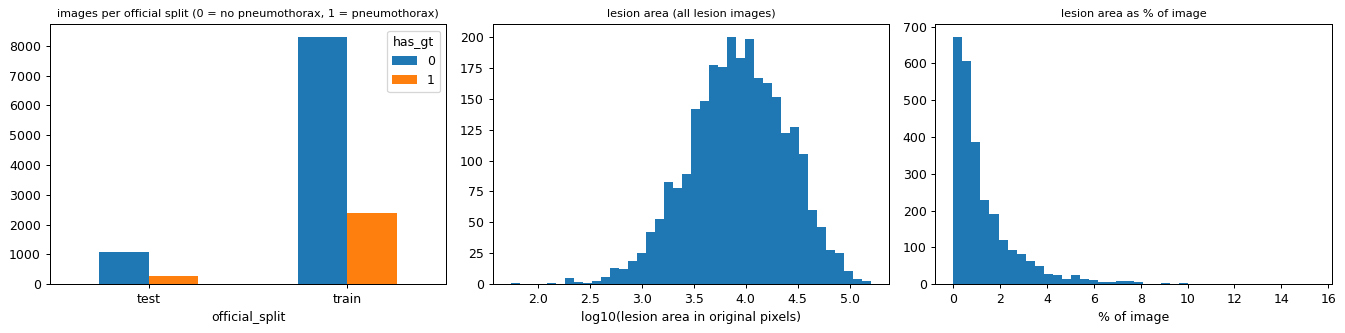

count      2669.0
mean      14331.0
std       16443.0
min          55.0
25%        4059.0
50%        8630.0
75%       18388.0
max      161421.0


In [14]:
# ---- resolution check: how much does evaluating at IMG_SIZE instead of the original resolution change the ground truth? ----
cand = meta[(meta.official_split == "train") & (meta.has_gt == 1)]
cand = cand.sample(min(150, len(cand)), random_state=0)
dd = []
for i, r in cand.iterrows():
    m0 = cv2.imread(str(root / "png_masks" / r.file), 0) > 0
    up = cv2.resize(np.asarray(cache["masks"][i]).astype(np.uint8), m0.shape[::-1], interpolation=cv2.INTER_NEAREST) > 0
    dd.append(2 * (m0 & up).sum() / max(1, m0.sum() + up.sum()))
print(f"Dice between the ORIGINAL mask and the {IMG_SIZE}-px mask upsampled back (n={len(dd)} lesion masks): "
      f"mean {np.mean(dd):.4f}, min {np.min(dd):.4f}")
print("=> this is the ceiling imposed by evaluating at the reduced resolution; metrics below are computed on the reduced grid.")

# ---- class distribution + lesion size ----
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ct = meta.groupby(["official_split", "has_gt"]).size().unstack(fill_value=0)
ct.plot.bar(ax=ax[0], rot=0); ax[0].set_title("images per official split (0 = no pneumothorax, 1 = pneumothorax)", fontsize=9)
pos = meta[meta.has_gt == 1]
ax[1].hist(np.log10(pos.fg_orig.clip(lower=1)), bins=40); ax[1].set_xlabel("log10(lesion area in original pixels)"); ax[1].set_title("lesion area (all lesion images)", fontsize=9)
ax[2].hist(pos.fg_orig / (pos.img_h * pos.img_w) * 100, bins=40); ax[2].set_xlabel("% of image"); ax[2].set_title("lesion area as % of image", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "dataset_distribution.png", dpi=130); plt.show()
print(pos.fg_orig.describe().round(0).to_string())

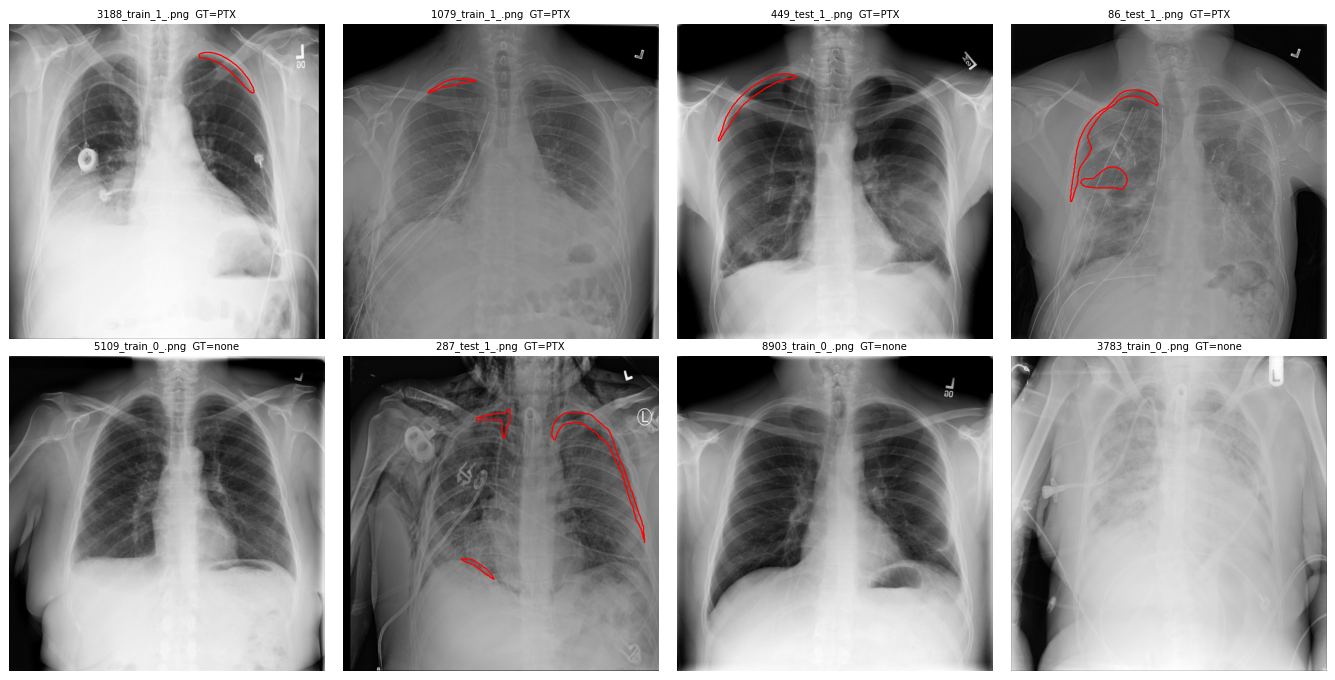

In [15]:
# ---- visual check: images with mask outlines (cached 512-px arrays) ----
rs = np.random.default_rng(1)
pos_i = rs.choice(meta.index[(meta.has_gt == 1)], 5, replace=False); neg_i = rs.choice(meta.index[(meta.has_gt == 0)], 3, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(15, 7.6))
for a, i in zip(ax.ravel(), list(pos_i[:4]) + list(neg_i[:1]) + list(pos_i[4:]) + list(neg_i[1:])):
    a.imshow(cache["images"][i], cmap="gray")
    if cache["masks"][i].any(): a.contour(cache["masks"][i], [0.5], colors="red", linewidths=1)
    a.set_title(f"{meta.file[i]}  GT={'PTX' if meta.has_gt[i] else 'none'}", fontsize=8); a.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "dataset_samples.png", dpi=120); plt.show()

In [16]:
# ---- train / validation split of the OFFICIAL TRAIN data; the official test split stays untouched until section 8 ----
meta = C.make_split(meta, VAL_FRAC, SEED)
print(meta.groupby(["split", "has_gt"]).size().unstack().assign(total=lambda d: d.sum(1)).to_string())
print("\npositive rate:", meta.groupby("split").has_gt.mean().round(4).to_dict())
small_edges = C.small_lesion_edges(meta)
print(f"lesion-size strata (tertiles of TRAIN lesion area at {IMG_SIZE}px): small <= {small_edges[0]:.0f} px < medium <= {small_edges[1]:.0f} px < large")
meta[["file", "official_split", "split", "has_gt", "name_label", "fg_orig", "fg_resized", "md5"]].to_csv(RES_DIR / "split_manifest.csv", index=False)
(RES_DIR / "split_info.json").write_text(json.dumps(dict(seed=SEED, val_frac=VAL_FRAC, small_edges=small_edges, img_size=IMG_SIZE)))
train_idx = meta.index[meta.split == "train"].values
val_idx = meta.index[meta.split == "val"].values
train_labels = meta.loc[train_idx, "has_gt"].values
dup_cross = meta.groupby("md5").split.nunique()
print("identical-image groups spanning train/val:", int((dup_cross > 1).sum()), "(0 expected; duplicates are grouped by MD5)")
print("NOTE: the PNG dataset has no patient ID, so patient-level grouping cannot be verified; only exact duplicates are controlled.")
# the test indices are deliberately NOT created here

has_gt     0     1  total
split                    
test    1082   290   1372
train   7466  2141   9607
val      830   238   1068

positive rate: {'test': 0.2114, 'train': 0.2229, 'val': 0.2228}
lesion-size strata (tertiles of TRAIN lesion area at 512px): small <= 1329 px < medium <= 3423 px < large
identical-image groups spanning train/val: 1 (0 expected; duplicates are grouped by MD5)
NOTE: the PNG dataset has no patient ID, so patient-level grouping cannot be verified; only exact duplicates are controlled.


## 4. Synthetic ICU-artifact generator (visual check)
Three **training** families (ECG wires with electrode discs, chest drainage tubes, monitoring lines) and one **unseen** family (central catheter with pigtail loop, never used in training).
Severity 1 / 2 / 3 controls count, width and opacity. The pneumothorax mask is never changed. These are procedurally drawn stress tests, **not** a clinical simulation.

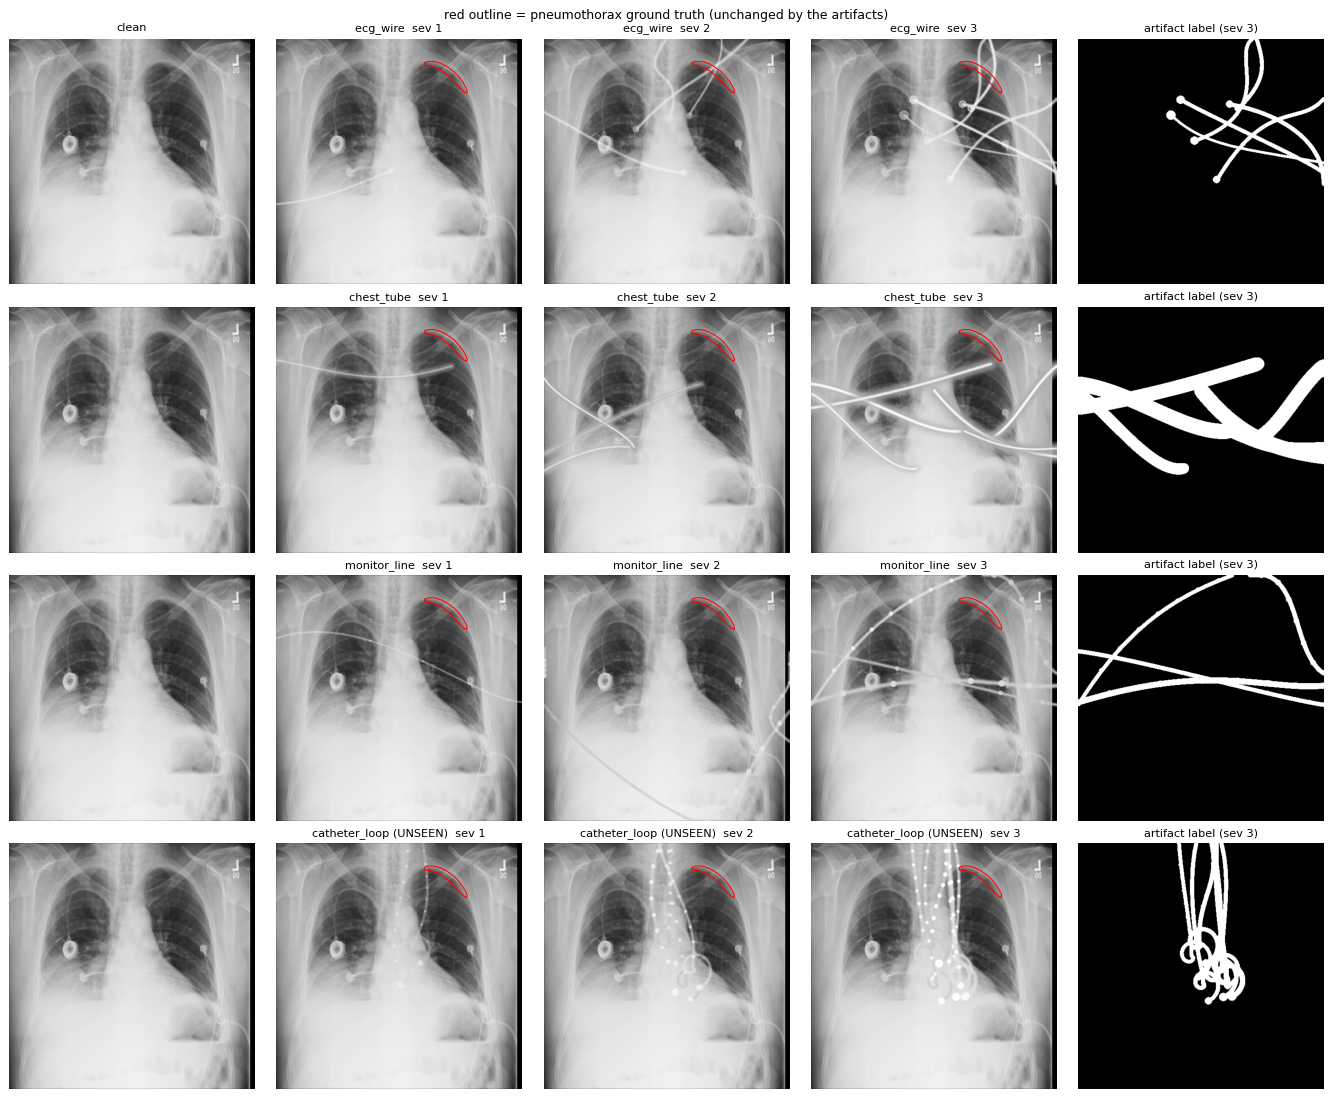

check passed: the pneumothorax mask is identical before/after artifact overlay


In [17]:
i0 = int(pos_i[0])
base = np.asarray(cache["images"][i0]).astype(np.float32) / 255.0
fig, ax = plt.subplots(4, 5, figsize=(15, 12.4))
for r, fam in enumerate(ALL_FAMILIES):
    ax[r, 0].imshow(base, cmap="gray", vmin=0, vmax=1); ax[r, 0].set_title("clean" if r == 0 else "", fontsize=9)
    for c, sev in enumerate((1, 2, 3), start=1):
        o, lab, _ = add_artifacts(base, np.random.default_rng(10 * r + c), [fam], sev)
        ax[r, c].imshow(o, cmap="gray", vmin=0, vmax=1); ax[r, c].contour(cache["masks"][i0], [0.5], colors="red", linewidths=.8)
        ax[r, c].set_title(f"{fam}{' (UNSEEN)' if fam == UNSEEN_FAMILY else ''}  sev {sev}", fontsize=9)
    ax[r, 4].imshow(lab, cmap="gray"); ax[r, 4].set_title("artifact label (sev 3)", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.suptitle("red outline = pneumothorax ground truth (unchanged by the artifacts)", fontsize=10); plt.tight_layout()
plt.savefig(FIG_DIR / "artifact_gallery.png", dpi=110); plt.show()
ds_chk = PneumoDataset(CACHE, [i0], train=True, aug=AugConfig(hflip_p=0, affine_p=0), art_mix=1.0)
assert np.array_equal(ds_chk[0]["mask"][0].numpy().astype(np.uint8), np.asarray(cache["masks"][i0])), "artifact overlay changed the mask!"
print("check passed: the pneumothorax mask is identical before/after artifact overlay")

## 5. Model tests, GPU memory probe, measured speed, smoke tests

In [18]:
# ---- forward-pass test of every model variant: shapes, auxiliary outputs, parameter counts ----
rows = []
for r in RUNS:
    cfg = dict(r.model_cfg); cfg["pretrained"] = False
    m = build_model(r.kind, cfg).to(DEVICE).train()
    x = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    with torch.no_grad():
        o = m(x)
    assert o["seg"].shape == (2, 1, IMG_SIZE, IMG_SIZE), o["seg"].shape
    if "artifact" in o: assert o["artifact"].shape == (2, 1, IMG_SIZE, IMG_SIZE)
    rows.append(dict(run=r.name, params_M=round(count_parameters(m)["total"] / 1e6, 2), seg=tuple(o["seg"].shape), artifact="artifact" in o,
                     aux=[tuple(a.shape[-2:]) for a in o.get("aux", [])]))
    del m, o
if HAS_CUDA: torch.cuda.empty_cache()
display(pd.DataFrame(rows))
# ---- loss + gradient sanity on one real augmented batch ----
b = next(iter(torch.utils.data.DataLoader(PneumoDataset(CACHE, train_idx[:8], train=True, art_mix=1.0), batch_size=4)))
m = build_model("aa", dict(AA_FULL, pretrained=False)).to(DEVICE).train()
o = m(to_model_input(b["image"].to(DEVICE)))
loss, parts = compute_loss(o, b["mask"].to(DEVICE), b["art"].to(DEVICE), b["has_art"].to(DEVICE), LossConfig())
loss.backward()
print({k: round(float(v), 4) for k, v in parts.items()}, "| all params got gradients:", all(p.grad is not None for p in m.parameters() if p.requires_grad))
del m, o, loss

,run,params_M,seg,artifact,aux
0,aa_artifact,20.06,"(2, 1, 512, 512)",True,"[(32, 32), (64, 64), (128, 128), (256, 256)]"
1,baseline_std,19.41,"(2, 1, 512, 512)",False,[]


{'seg': 3.8088, 'ds': 4.1046, 'art': 3.221, 'total': 6.6506} | all params got gradients: True


In [19]:
# ---- GPU memory probe (largest micro-batch that fits a full training step) + measured speed ----
probe_run = RUN_BY_NAME[MAIN_PROPOSED]
print("probing micro-batch for the heaviest single model (AA full) ...")
MICRO_BS = E.probe_micro_batch(probe_run, tc, DEVICE)
MICRO_BS = max(1, min(MICRO_BS, EFFECTIVE_BS))
MICRO_BS = min(MICRO_BS, 4)   # safety cap: the probe under-estimates real training memory (OOM seen at 8); gradient accumulation keeps effective batch = 8
while EFFECTIVE_BS % MICRO_BS: MICRO_BS -= 1
print(f"-> micro-batch {MICRO_BS} x gradient accumulation {EFFECTIVE_BS // MICRO_BS} = effective batch {EFFECTIVE_BS}")
if any(r.consistency for r in RUNS):
    print("(the consistency run uses half the micro-batch because it processes clean+corrupted pairs)")

def measure_speed(run, mb, n_warm=3, n_time=8):
    cfg = dict(run.model_cfg); cfg["pretrained"] = False
    model = build_model(run.kind, cfg).to(DEVICE).train(); opt = torch.optim.AdamW(model.parameters(), 1e-5)
    sc = torch.amp.GradScaler("cuda", enabled=AMP)
    n = mb * (2 if run.consistency else 1)
    x = torch.rand(n, 1, IMG_SIZE, IMG_SIZE, device=DEVICE); y = (torch.rand_like(x) > 0.99).float()
    for i in range(n_warm + n_time):
        if i == n_warm:
            if HAS_CUDA: torch.cuda.synchronize()
            t = time.perf_counter()
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
            out = model(to_model_input(x))
        l, _ = compute_loss(out, y, y, torch.ones(n, device=DEVICE), LossConfig(), cons_pair=run.consistency)
        opt.zero_grad(); sc.scale(l).backward(); sc.step(opt); sc.update()
    if HAS_CUDA: torch.cuda.synchronize()
    del model, opt
    return (time.perf_counter() - t) / (n_time * mb)         # seconds per training image (GPU only)

def measure_loader(run, mb, n_batches=12):
    ds = PneumoDataset(CACHE, train_idx, train=True, art_mix=run.art_mix, pair=run.consistency)
    dl = E.make_loader(ds, mb, shuffle=True, workers=WORKERS, drop_last=True)
    t = None
    for i, _ in enumerate(dl):
        if i == 2: t = time.perf_counter()
        if i == 2 + n_batches: break
    return (time.perf_counter() - t) / (n_batches * mb)       # seconds per image (data pipeline only)

n_epoch_imgs = len(EpochSampler(train_labels, NEG_FRAC))
rows = []
for r in RUNS:
    mb = max(1, MICRO_BS // 2) if r.consistency else MICRO_BS
    g, l = measure_speed(r, mb), measure_loader(r, mb)
    ep = n_epoch_imgs * max(g, l) + len(val_idx) * g / 3.0
    rows.append(dict(run=r.name, gpu_img_s=round(1 / g, 1), loader_img_s=round(1 / l, 1), bottleneck="GPU" if g >= l else "data loading",
                     epoch_min=round(ep / 60, 1), run_hours=round(ep * r.epochs / 3600, 2)))
speed = pd.DataFrame(rows); display(speed)
total_h = speed.run_hours.sum(); budget_h = SESSION_BUDGET_HOURS - EVAL_RESERVE_HOURS
print(f"\nPROJECTED training time for all {len(RUNS)} runs: {total_h:.1f} h  (training budget in this session: {budget_h:.1f} h; "
      f"{n_epoch_imgs} training images per epoch)")
if total_h > budget_h:
    print("=> not everything fits in one session. Tier-1 runs go first; training pauses cleanly at the budget and resumes next session "
          "(see the note at the top). You can also lower EPOCHS/NEG_FRAC or set RUN_ABLATIONS=False.")
speed.to_csv(RES_DIR / "measured_speed.csv", index=False)

probing micro-batch for the heaviest single model (AA full) ...
  [probe] micro-batch 8: peak 11.3 GB of 15.6 GB
-> micro-batch 4 x gradient accumulation 2 = effective batch 8


,run,gpu_img_s,loader_img_s,bottleneck,epoch_min,run_hours
0,aa_artifact,12.3,93.7,GPU,8.5,1.41
1,baseline_std,21.9,126.7,GPU,4.7,0.79



PROJECTED training time for all 2 runs: 2.2 h  (training budget in this session: 9.4 h; 5874 training images per epoch)


In [20]:
# ---- smoke test: every run type trains 1 short epoch end-to-end (training -> validation -> checkpoint) before the long runs start ----
import tempfile
SMOKE_DIR = Path(tempfile.mkdtemp(prefix="smoke_"))
tc_smoke = E.TrainConfig(**{**E.asdict(tc), "log_every": 10**9, "min_epochs": 1})
t0 = time.time()
for r in RUNS:
    rs_ = E.RunConfig(**{**r.__dict__, "epochs": 1})
    mb = max(1, MICRO_BS // 2) if r.consistency else MICRO_BS
    st = E.train_run(rs_, tc_smoke, CACHE, train_idx, val_idx[:48], train_labels, SMOKE_DIR / r.name, micro_bs=mb,
                     max_train_samples=max(16, 4 * EFFECTIVE_BS), log=lambda *a: None)
    h = pd.read_csv(SMOKE_DIR / r.name / "history.csv").iloc[-1]
    assert np.isfinite(h.train_total) and np.isfinite(h.val_loss), f"{r.name}: non-finite loss in smoke test"
    assert (SMOKE_DIR / r.name / "best.pt").exists() and (SMOKE_DIR / r.name / "last.pt").exists()
    print(f"smoke OK  {r.name:22s} train_loss {h.train_total:.3f}  val_loss {h.val_loss:.3f}  {h.secs:.0f}s")
shutil.rmtree(SMOKE_DIR, ignore_errors=True)
print(f"all smoke tests passed in {time.time() - t0:.0f}s")

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


smoke OK  aa_artifact            train_loss 6.573  val_loss 3.101  5s


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


smoke OK  baseline_std           train_loss 3.944  val_loss 2.581  4s
all smoke tests passed in 11s


## 6. Training
Each run: AdamW (encoder lr 2e-4, new layers 6e-4, wd 1e-4), 1-epoch warm-up then cosine decay, fp16 mixed precision, gradient clipping 1.0, early stopping (patience 6 after epoch 8).
Loss (both models): **BCE + batch-level soft Dice**; AA adds deep supervision (0.3), artifact loss on corrupted samples only (0.5), and — in the consistency ablation — a clean↔corrupted consistency term (0.5).
Model selection: best validation **Dice over all images** (empty convention) on a (threshold × min-area) grid, **clean validation only**. Checkpoints (`last.pt`, `best.pt`) are written atomically, and the previous file is kept as `.prev`.

In [21]:
# ---- resume support: import runs saved by a previous version of this notebook (added as an input) ----
def restore_previous_outputs():
    base = Path("/kaggle/input")
    if not base.exists(): return
    n = 0
    for d in base.glob("**/runs"):
        if d.resolve() == RUNS_DIR.resolve() or not d.is_dir(): continue
        for rd in d.iterdir():
            if rd.is_dir() and rd.name in RUN_BY_NAME and (rd / "last.pt").exists() and not (RUNS_DIR / rd.name).exists():
                shutil.copytree(rd, RUNS_DIR / rd.name); n += 1; print("restored run from previous version:", rd)
    if n == 0: print("no previous runs found in /kaggle/input (starting fresh)")
restore_previous_outputs()

no previous runs found in /kaggle/input (starting fresh)


In [22]:
STATUS = {}
labels_arr = train_labels
print(f"training budget ends in {(DEADLINE - time.time()) / 3600:.1f} h from now\n")
for r in RUNS:
    print("=" * 110 + f"\nRUN {r.name}: {r.description}\n" + "=" * 110)
    mb = max(1, MICRO_BS // 2) if r.consistency else MICRO_BS
    try:
        STATUS[r.name] = E.train_run(r, tc, CACHE, train_idx, val_idx, labels_arr, RUNS_DIR / r.name, micro_bs=mb, deadline=DEADLINE)
    except Exception as e:
        import traceback, gc; traceback.print_exc()
        STATUS[r.name] = dict(status="failed", error=repr(e))
        del e; gc.collect()                      # release tensors held by the failed run's traceback, otherwise the next run also OOMs
        if HAS_CUDA: torch.cuda.empty_cache()
        continue
    if STATUS[r.name]["status"] == "paused":
        print("\nTime budget reached: remaining runs are deferred to the next session (see instructions at the top)."); break
print("\n" + "=" * 60); display(pd.DataFrame(STATUS).T)

training budget ends in 8.5 h from now

RUN aa_artifact: PROPOSED: AA-HybridUNet + synthetic-artifact training


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[aa_artifact] new run: 20.06 M params, micro-batch 4 x accum 2 = effective 8, 1468 micro-steps/epoch, 10 epochs
  [aa_artifact] ep 1/10 step 100/734 seg=2.758 ds=1.995 art=2.708 total=4.711 lr=1.08e-04 68s
  [aa_artifact] ep 1/10 step 200/734 seg=1.935 ds=1.565 art=1.974 total=3.391 lr=1.85e-04 134s
  [aa_artifact] ep 1/10 step 300/734 seg=1.631 ds=1.366 art=1.513 total=2.797 lr=2.63e-04 201s
  [aa_artifact] ep 1/10 step 400/734 seg=1.454 ds=1.249 art=1.249 total=2.453 lr=3.41e-04 267s
  [aa_artifact] ep 1/10 step 500/734 seg=1.332 ds=1.172 art=1.072 total=2.220 lr=4.18e-04 334s
  [aa_artifact] ep 1/10 step 600/734 seg=1.251 ds=1.115 art=0.950 total=2.061 lr=4.96e-04 400s
  [aa_artifact] ep 1/10 step 700/734 seg=1.188 ds=1.072 art=0.858 total=1.939 lr=5.74e-04 467s
[aa_artifact] epoch 1/10 | train_loss 1.9034 | val_loss 0.8191 | val Dice_all 0.7979 (Dice_pos 0.2778 @thr 0.7, min_img 1000) | img AUC 0.869 | 517s (train 489s)  * best
  [aa_artifact] ep 2/10 step 100/734 seg=0.752 ds=0.73

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[baseline_std] new run: 19.41 M params, micro-batch 4 x accum 2 = effective 8, 1468 micro-steps/epoch, 10 epochs
  [baseline_std] ep 1/10 step 100/734 seg=3.153 total=3.153 lr=1.08e-04 38s
  [baseline_std] ep 1/10 step 200/734 seg=2.275 total=2.275 lr=1.85e-04 76s
  [baseline_std] ep 1/10 step 300/734 seg=1.876 total=1.876 lr=2.63e-04 114s
  [baseline_std] ep 1/10 step 400/734 seg=1.666 total=1.666 lr=3.41e-04 152s
  [baseline_std] ep 1/10 step 500/734 seg=1.521 total=1.521 lr=4.18e-04 190s
  [baseline_std] ep 1/10 step 600/734 seg=1.417 total=1.417 lr=4.96e-04 228s
  [baseline_std] ep 1/10 step 700/734 seg=1.335 total=1.335 lr=5.74e-04 266s
[baseline_std] epoch 1/10 | train_loss 1.3104 | val_loss 0.8695 | val Dice_all 0.8124 (Dice_pos 0.2168 @thr 0.4, min_img 1000) | img AUC 0.805 | 293s (train 278s)  * best
  [baseline_std] ep 2/10 step 100/734 seg=0.750 total=0.750 lr=6.00e-04 38s
  [baseline_std] ep 2/10 step 200/734 seg=0.753 total=0.753 lr=5.99e-04 76s
  [baseline_std] ep 2/10 st

,status,epochs_run,best_val_dice_all,best_epoch,mean_epoch_secs,finished
aa_artifact,done,10,0.84808,7,513.346413,2026-10-21 11:35:28
baseline_std,done,10,0.846396,8,292.039627,2026-10-21 12:24:13


runs with a trained checkpoint: ['aa_artifact', 'baseline_std']


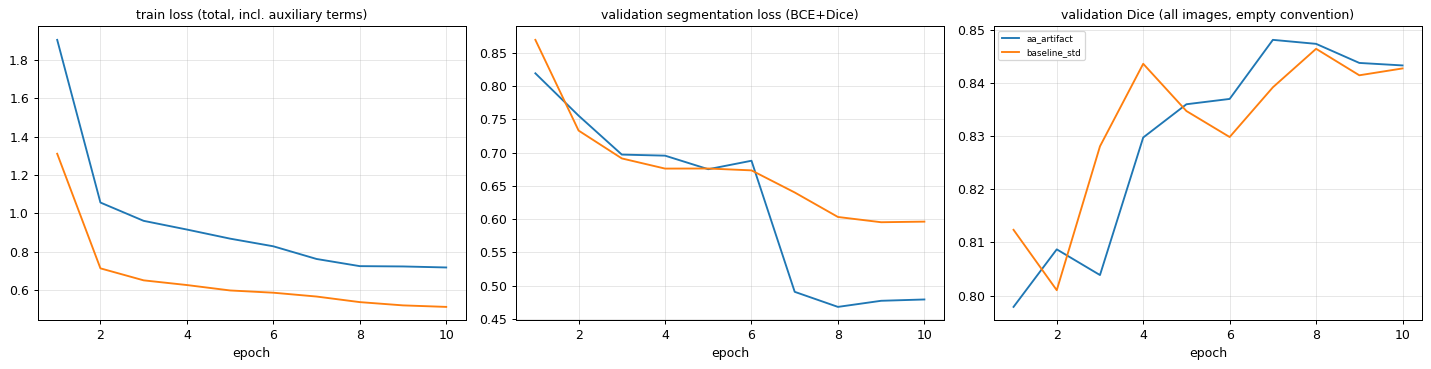

,run,epochs_run,of,best_epoch,best_val_dice_all,val_dice_lesion_imgs,val_img_auc,mean_epoch_min,complete
0,aa_artifact,10,10,7,0.8481,0.4401,0.8977,8.6,True
1,baseline_std,10,10,8,0.8464,0.4536,0.9143,4.9,True


In [23]:
TRAINED = [r.name for r in RUNS if (RUNS_DIR / r.name / "best.pt").exists()]
print("runs with a trained checkpoint:", TRAINED)
if not TRAINED: raise SystemExit("no trained run available - nothing to evaluate")
R.plot_training_curves(RUNS_DIR, TRAINED, FIG_DIR / "training_curves.png"); plt.show()
summ = []
for n in TRAINED:
    h = pd.read_csv(RUNS_DIR / n / "history.csv"); b = h.loc[h.val_dice_all.idxmax()]
    summ.append(dict(run=n, epochs_run=len(h), of=RUN_BY_NAME[n].epochs, best_epoch=int(b.epoch), best_val_dice_all=round(b.val_dice_all, 4),
                     val_dice_lesion_imgs=round(b.val_dice_pos, 4), val_img_auc=round(b.val_img_auc, 4), mean_epoch_min=round(h.secs.mean() / 60, 1),
                     complete=(RUNS_DIR / n / "done.json").exists()))
display(pd.DataFrame(summ)); pd.DataFrame(summ).to_csv(RES_DIR / "training_summary.csv", index=False)

## 7. Validation: operating-point tuning and clean / artifact-corrupted validation
Threshold, minimum component area and minimum image-level area are tuned **on the validation split only** (objective: Dice over all images; ties → Dice on lesion images),
separately for each model, using the same grid. The tuned operating point is then frozen and applied to the test split.

,thr,min_comp,min_img,val_dice_all_tuned,val_dice_pos_tuned,val_dice_all_default,val_dice_pos_default
run,,,,,,,
aa_artifact,0.80,1000,0,0.8508,0.4273,0.8181,0.4864
baseline_std,0.75,1000,0,0.8487,0.4470,0.8185,0.5008


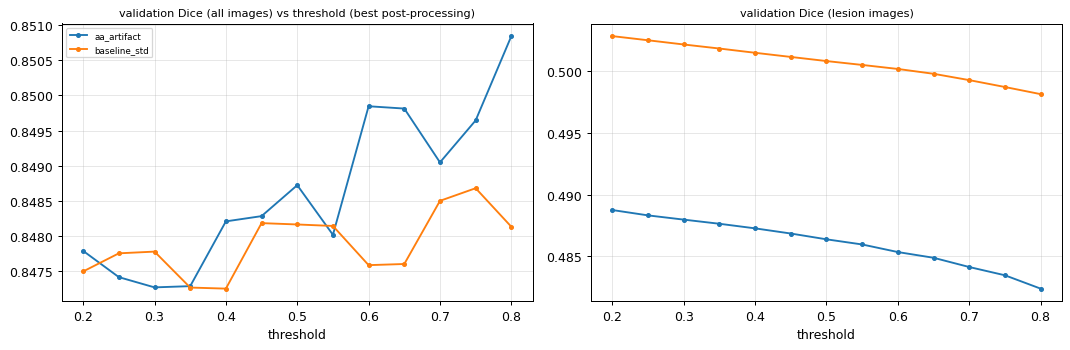

In [24]:
def load_run_model(name):
    ck = E.load_ckpt(RUNS_DIR / name / "best.pt", "cpu")
    cfg = dict(ck["model_cfg"]); cfg["pretrained"] = False          # weights come from the checkpoint
    m = build_model(ck["kind"], cfg); m.load_state_dict(ck["model"], strict=True)
    return m.to(DEVICE).eval(), ck

gts_val = E.gather_gts(CACHE, val_idx)
OPS, GRIDS = {}, {}
for n in TRAINED:
    op_p, gr_p = RUNS_DIR / n / "operating_point.json", RUNS_DIR / n / "val_tuning_grid.csv"
    if op_p.exists() and gr_p.exists() and not FORCE_REEVAL:
        OPS[n], GRIDS[n] = json.loads(op_p.read_text()), pd.read_csv(gr_p); continue
    model, ck = load_run_model(n)
    probs = E.predict_probs(model, PneumoDataset(CACHE, val_idx, train=False), DEVICE, bs=16, workers=WORKERS, amp=AMP)
    OPS[n], GRIDS[n] = M.tune_postprocess(probs, gts_val, THRS, MIN_COMPS, MIN_IMGS)
    op_p.write_text(json.dumps(OPS[n])); GRIDS[n].to_csv(gr_p, index=False)
    del probs, model
    if HAS_CUDA: torch.cuda.empty_cache()
rows = []
for n in TRAINED:
    g = GRIDS[n]; d0 = g[(g.thr == 0.5) & (g.min_comp == 0) & (g.min_img == 0)]
    rows.append(dict(run=n, **OPS[n], val_dice_all_tuned=round(g.dice_all.iloc[0], 4), val_dice_pos_tuned=round(g.dice_pos.iloc[0], 4),
                     val_dice_all_default=round(float(d0.dice_all.iloc[0]), 4) if len(d0) else np.nan,
                     val_dice_pos_default=round(float(d0.dice_pos.iloc[0]), 4) if len(d0) else np.nan))
OP_TABLE = pd.DataFrame(rows).set_index("run"); display(OP_TABLE); OP_TABLE.to_csv(RES_DIR / "operating_points_val.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n in TRAINED:
    g = GRIDS[n]; s = g.groupby("thr")[["dice_all", "dice_pos"]].max()
    ax[0].plot(s.index, s.dice_all, marker=".", label=n); ax[1].plot(s.index, s.dice_pos, marker=".", label=n)
ax[0].set_title("validation Dice (all images) vs threshold (best post-processing)", fontsize=9); ax[1].set_title("validation Dice (lesion images)", fontsize=9)
for a in ax: a.set_xlabel("threshold"); a.grid(alpha=.3)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG_DIR / "val_threshold_sweep.png", dpi=120); plt.show()

In [25]:
# ---- clean and artifact-corrupted VALIDATION with the tuned operating points (no re-tuning) ----
VAL_CONDS = ["clean", "sev2", "sev3", "unseen_sev2"]
for n in TRAINED:
    print(f"[{n}]")
    model, _ = load_run_model(n)
    EV.evaluate_conditions(model, CACHE, val_idx, OPS[n], small_edges, VAL_CONDS, VAL_DIR / n, DEVICE, workers=WORKERS, amp=AMP, seed=SEED, force=FORCE_REEVAL)
    del model
    if HAS_CUDA: torch.cuda.empty_cache()
display(R.table_robustness(VAL_DIR, TRAINED))

[aa_artifact]
    clean        Dice_pos 0.4273  Dice_all 0.8508  sens 0.581  prec 0.690  HD95 77.6  img-AUC 0.897
    sev2         Dice_pos 0.4107  Dice_all 0.8415  sens 0.558  prec 0.665  HD95 78.5  img-AUC 0.889
    sev3         Dice_pos 0.3961  Dice_all 0.8345  sens 0.547  prec 0.656  HD95 73.5  img-AUC 0.878
    unseen_sev2  Dice_pos 0.3584  Dice_all 0.8364  sens 0.502  prec 0.709  HD95 74.9  img-AUC 0.867
[baseline_std]
    clean        Dice_pos 0.4470  Dice_all 0.8487  sens 0.597  prec 0.687  HD95 65.9  img-AUC 0.914
    sev2         Dice_pos 0.3884  Dice_all 0.8365  sens 0.523  prec 0.698  HD95 80.2  img-AUC 0.894
    sev3         Dice_pos 0.3331  Dice_all 0.8280  sens 0.463  prec 0.724  HD95 86.5  img-AUC 0.866
    unseen_sev2  Dice_pos 0.3491  Dice_all 0.8372  sens 0.475  prec 0.735  HD95 64.2  img-AUC 0.885


,Clean,"Seen, sev 2","Seen, sev 3","Unseen, sev 2",Drop sev 2 (abs),Drop sev 2 (%),Drop unseen sev 2 (abs),Drop unseen sev 2 (%)
aa_artifact,0.427,0.411,0.396,0.358,0.017,3.9,0.069,16.1
baseline_std,0.447,0.388,0.333,0.349,0.059,13.1,0.098,21.9


## 8. FINAL TEST EVALUATION (official test split — read only here)
Conditions: clean; seen device families at severity 1/2/3; the **unseen** family at severity 1/2/3. Corrupted images are generated with fixed seeds, so every model sees exactly the same pixels (paired comparison).
Synthetic robustness ≠ real-world clinical validation. All metrics are at the cache resolution; see the audit section for the resolution ceiling.

In [26]:
test_idx = meta.index[meta.split == "test"].values                # <- the only place the test split is selected
gts_test = E.gather_gts(CACHE, test_idx)
print(f"test images: {len(test_idx)} | lesion images: {int((gts_test.reshape(len(gts_test), -1).max(1) > 0).sum())}")
# fixed, model-independent selection of lesion images for the qualitative figure (spread over lesion sizes)
areas = gts_test.reshape(len(gts_test), -1).sum(1)
pos_pos = np.flatnonzero(areas > 0); order = pos_pos[np.argsort(areas[pos_pos])]
KEEP = [int(order[int(q * (len(order) - 1))]) for q in (0.1, 0.3, 0.5, 0.7, 0.9)]
FIG_RUNS = [n for n in (MAIN_BASELINE, "aa_std", MAIN_PROPOSED) if n in TRAINED]
KEEP_DATA = {}
for n in TRAINED:
    print(f"\n[{n}]  operating point (tuned on validation): {OPS[n]}")
    model, _ = load_run_model(n)
    res = EV.evaluate_conditions(model, CACHE, test_idx, OPS[n], small_edges, EV.COND_ORDER, TEST_DIR / n, DEVICE, workers=WORKERS, amp=AMP,
                                 seed=SEED, force=FORCE_REEVAL, keep_idx=KEEP if n in FIG_RUNS else ())
    if n in FIG_RUNS:
        KEEP_DATA[n] = {c: res[c]["_keep"] for c in ("clean", "sev2") if "_keep" in res.get(c, {})}
    # untuned reference: threshold 0.5, no post-processing
    EV.evaluate_conditions(model, CACHE, test_idx, M.DEFAULT_OP, small_edges, ["clean"], TEST_DIR / f"{n}__default_op", DEVICE, workers=WORKERS,
                           amp=AMP, seed=SEED, force=FORCE_REEVAL, log=lambda *a: None)
    del model
    if HAS_CUDA: torch.cuda.empty_cache()
print("\ntest evaluation finished.")

test images: 1372 | lesion images: 290

[aa_artifact]  operating point (tuned on validation): {'thr': 0.8, 'min_comp': 1000, 'min_img': 0}
    clean        Dice_pos 0.3998  Dice_all 0.8564  sens 0.550  prec 0.686  HD95 75.0  img-AUC 0.918
    sev1         Dice_pos 0.3953  Dice_all 0.8554  sens 0.547  prec 0.679  HD95 70.1  img-AUC 0.916
    sev2         Dice_pos 0.3915  Dice_all 0.8524  sens 0.549  prec 0.678  HD95 70.4  img-AUC 0.904
    sev3         Dice_pos 0.3733  Dice_all 0.8522  sens 0.515  prec 0.658  HD95 80.9  img-AUC 0.899
    unseen_sev1  Dice_pos 0.3778  Dice_all 0.8532  sens 0.530  prec 0.687  HD95 76.2  img-AUC 0.910
    unseen_sev2  Dice_pos 0.3528  Dice_all 0.8523  sens 0.493  prec 0.694  HD95 73.1  img-AUC 0.896
    unseen_sev3  Dice_pos 0.3035  Dice_all 0.8440  sens 0.417  prec 0.709  HD95 86.4  img-AUC 0.865

[baseline_std]  operating point (tuned on validation): {'thr': 0.75, 'min_comp': 1000, 'min_img': 0}
    clean        Dice_pos 0.4163  Dice_all 0.8613  sens 0.5

## 9. Efficiency, result tables and figures

In [27]:
# ---- computational efficiency (batch 1, 512x512 inference) ----
EFF = {}
for n in TRAINED:
    ep = RUNS_DIR / n / "efficiency.json"
    if ep.exists() and not FORCE_REEVAL: EFF[n] = json.loads(ep.read_text()); continue
    model, _ = load_run_model(n)
    EFF[n] = B.measure_efficiency(model, IMG_SIZE, DEVICE); ep.write_text(json.dumps(EFF[n], indent=1))
    del model
    if HAS_CUDA: torch.cuda.empty_cache()
T_EFF = R.table_efficiency(EFF); display(T_EFF)

,Params (M),GMACs,Latency fp32 (ms),Latency fp16 (ms),Peak mem fp16 (GB),Throughput (img/s),Device
aa_artifact,20.06,33.0,40.4,34.1,1.00,29.3,Tesla T4
baseline_std,19.41,17.9,24.6,21.3,0.59,46.9,Tesla T4


In [28]:
# ---- TABLE 1: PRIMARY COMPARISON - the two principal models only ----
PAIR = [n for n in (MAIN_BASELINE, MAIN_PROPOSED) if n in TRAINED]
if len(PAIR) == 2:
    T1 = R.table_main(TEST_DIR, PAIR, "clean")
    print("TABLE 1 - clean official test set (mean [95% bootstrap CI over images]; * = dominated by background pixels, see notes)")
    display(T1.T); R.save_table(T1, "table1_main_clean", TABLES_DIR, "Primary comparison on the clean official test set")
else:
    print("primary comparison needs both", MAIN_BASELINE, "and", MAIN_PROPOSED, "- not both trained yet"); T1 = None
# ---- TABLE 2: robustness (Dice on lesion images per condition) ----
T2 = R.table_robustness(TEST_DIR, TRAINED, "dice_pos"); print("\nTABLE 2 - robustness to synthetic artifacts: Dice (lesion images)"); display(T2)
R.save_table(T2, "table2_robustness_dice_pos", TABLES_DIR); R.save_table(R.table_robustness(TEST_DIR, TRAINED, "dice_all"), "table2b_robustness_dice_all", TABLES_DIR)
# ---- TABLE 3: lesion size ----
T3 = R.table_lesion_size(TEST_DIR, TRAINED); print("\nTABLE 3 - Dice and lesion detection rate by lesion size (clean)"); display(T3); R.save_table(T3, "table3_lesion_size", TABLES_DIR)
# ---- TABLE 4: efficiency ----
print("\nTABLE 4 - efficiency"); display(T_EFF); R.save_table(T_EFF, "table4_efficiency", TABLES_DIR)
# ---- TABLE 5: all runs incl. ablations (internal) ----
T5 = R.table_main(TEST_DIR, TRAINED, "clean"); print("\nTABLE 5 - all runs (ablations/controls are INTERNAL comparisons), clean test"); display(T5.T); R.save_table(T5, "table5_all_runs_clean", TABLES_DIR)
# ---- TABLE 6: paired statistics ----
pairs = [p for p in [(MAIN_BASELINE, MAIN_PROPOSED), (MAIN_BASELINE, "aa_std"), ("aa_std", MAIN_PROPOSED), ("ctrl_baseline_artaug", MAIN_PROPOSED),
                     (MAIN_PROPOSED, "abl_no_gates"), (MAIN_PROPOSED, "abl_consistency")] if p[0] in TRAINED and p[1] in TRAINED]
T6 = R.table_stats(TEST_DIR, pairs); print("\nTABLE 6 - paired per-image comparison of Dice (B - A), bootstrap 95% CI and Wilcoxon signed-rank test")
display(T6); R.save_table(T6, "table6_paired_statistics", TABLES_DIR)
# ---- TABLE 7: tuned vs untuned operating point ----
rows = {}
for n in TRAINED:
    s_t, s_d = R.load_summaries(TEST_DIR, n, ["clean"]).get("clean"), R.load_summaries(TEST_DIR, f"{n}__default_op", ["clean"]).get("clean")
    if s_t and s_d:
        rows[n] = {"tuned op": str(OPS[n]), "Dice lesion (tuned)": round(s_t["dice_pos"], 4), "Dice all (tuned)": round(s_t["dice_all"], 4),
                   "Dice lesion (thr 0.5, no post-proc)": round(s_d["dice_pos"], 4), "Dice all (thr 0.5, no post-proc)": round(s_d["dice_all"], 4)}
T7 = pd.DataFrame(rows).T; print("\nTABLE 7 - effect of the validation-tuned operating point"); display(T7); R.save_table(T7, "table7_operating_point_effect", TABLES_DIR)
# ---- TABLE 8: ablation summary ----
abl_order = [n for n in ("baseline_std", "ctrl_baseline_artaug", "aa_std", "abl_no_gates", "aa_artifact", "abl_consistency") if n in TRAINED]
rows = {}
for n in abl_order:
    s = R.load_summaries(TEST_DIR, n)
    if "clean" in s:
        rows[n] = {"Dice clean": round(s["clean"]["dice_pos"], 4), "Dice seen sev2": round(s["sev2"]["dice_pos"], 4) if "sev2" in s else np.nan,
                   "Dice seen sev3": round(s["sev3"]["dice_pos"], 4) if "sev3" in s else np.nan,
                   "Dice UNSEEN sev2": round(s["unseen_sev2"]["dice_pos"], 4) if "unseen_sev2" in s else np.nan,
                   "Params (M)": round(EFF[n]["params_M"], 2), "GMACs": round(EFF[n]["gmacs"], 1)}
T8 = pd.DataFrame(rows).T; print("\nTABLE 8 - ablation / control summary (Dice on lesion images)"); display(T8); R.save_table(T8, "table8_ablation", TABLES_DIR)
# overwrite the empty templates with the measured tables
R.save_table(T1 if T1 is not None else EMPTY["table1_main_clean"], "table1_main_clean_FILLED", TABLES_DIR)

TABLE 1 - clean official test set (mean [95% bootstrap CI over images]; * = dominated by background pixels, see notes)


,baseline_std,aa_artifact
Dice (lesion imgs),"0.416 [0.374, 0.457]","0.400 [0.357, 0.440]"
Dice (all imgs),"0.861 [0.845, 0.877]","0.856 [0.840, 0.872]"
IoU (lesion imgs),"0.331 [0.295, 0.365]","0.318 [0.282, 0.352]"
Sensitivity,0.574,0.550
Precision,0.669,0.686
Specificity*,0.999,0.999
MCC,0.618,0.613
HD95 (px),67.35,74.95
HD95 penalised (px),320.99,334.60
Boundary F1,0.228,0.229



TABLE 2 - robustness to synthetic artifacts: Dice (lesion images)


,Clean,"Seen, sev 1","Seen, sev 2","Seen, sev 3","Unseen, sev 1","Unseen, sev 2","Unseen, sev 3",Drop sev 2 (abs),Drop sev 2 (%),Drop unseen sev 2 (abs),Drop unseen sev 2 (%)
aa_artifact,0.400,0.395,0.392,0.373,0.378,0.353,0.303,0.008,2.1,0.047,11.8
baseline_std,0.416,0.394,0.367,0.302,0.388,0.332,0.268,0.049,11.8,0.085,20.4



TABLE 3 - Dice and lesion detection rate by lesion size (clean)


,Dice small (n=80),Lesion DR small,Dice medium (n=108),Lesion DR medium,Dice large (n=102),Lesion DR large
aa_artifact,0.157,0.237,0.377,0.412,0.614,0.649
baseline_std,0.182,0.254,0.406,0.458,0.611,0.655


... (6 outputs left out)


TABLE 7 - effect of the validation-tuned operating point


,tuned op,Dice lesion (tuned),Dice all (tuned),"Dice lesion (thr 0.5, no post-proc)","Dice all (thr 0.5, no post-proc)"
aa_artifact,"{'thr': 0.8, 'min_comp': 1000, 'min_img': 0}",0.3998,0.8564,0.4748,0.838
baseline_std,"{'thr': 0.75, 'min_comp': 1000, 'min_img': 0}",0.4163,0.8613,0.4806,0.8341



TABLE 8 - ablation / control summary (Dice on lesion images)


,Dice clean,Dice seen sev2,Dice seen sev3,Dice UNSEEN sev2,Params (M),GMACs
baseline_std,0.4163,0.3673,0.3020,0.3315,19.41,17.9
aa_artifact,0.3998,0.3915,0.3733,0.3528,20.06,33.0


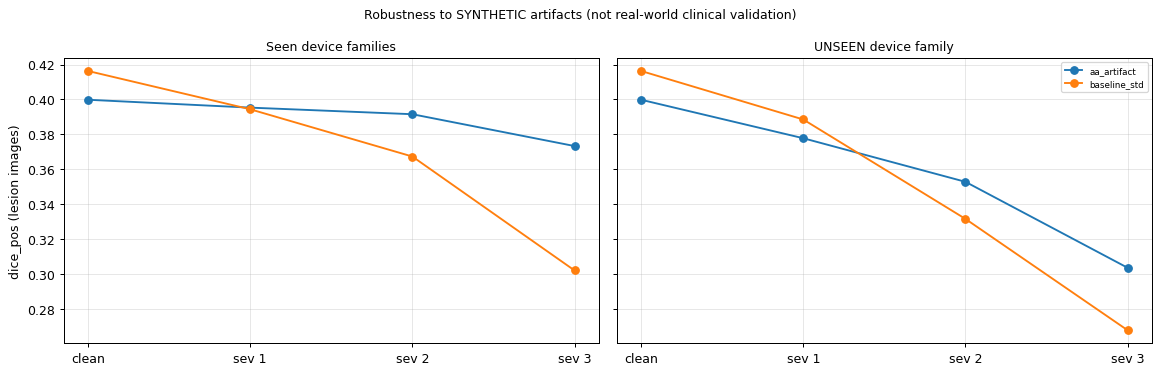

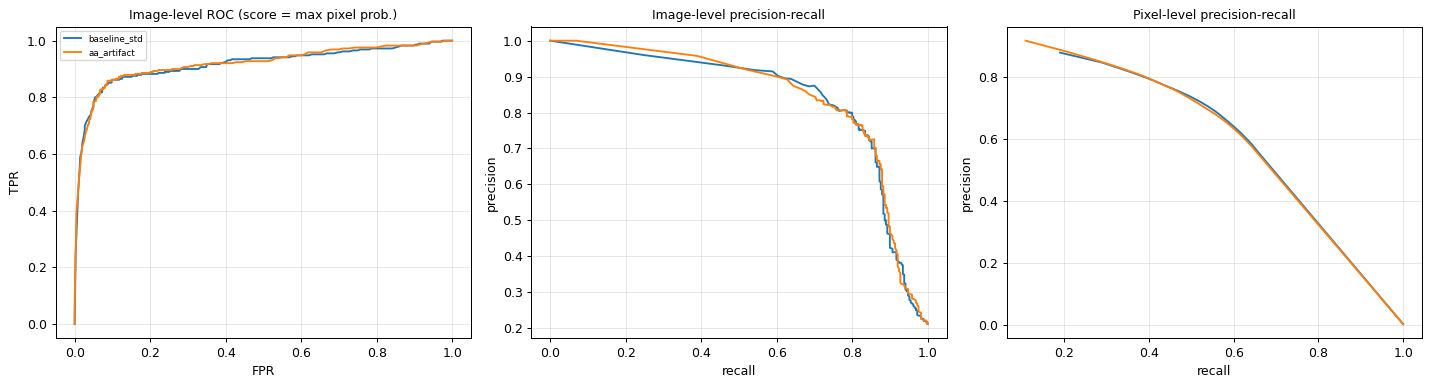

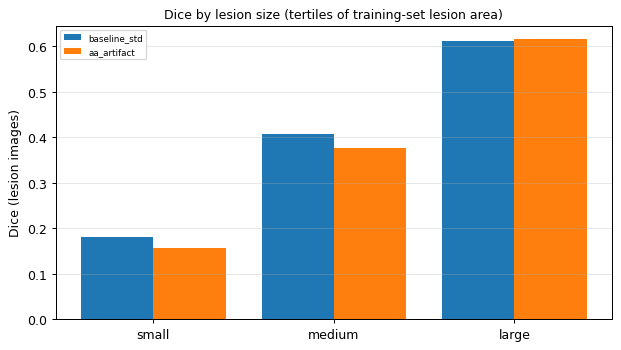

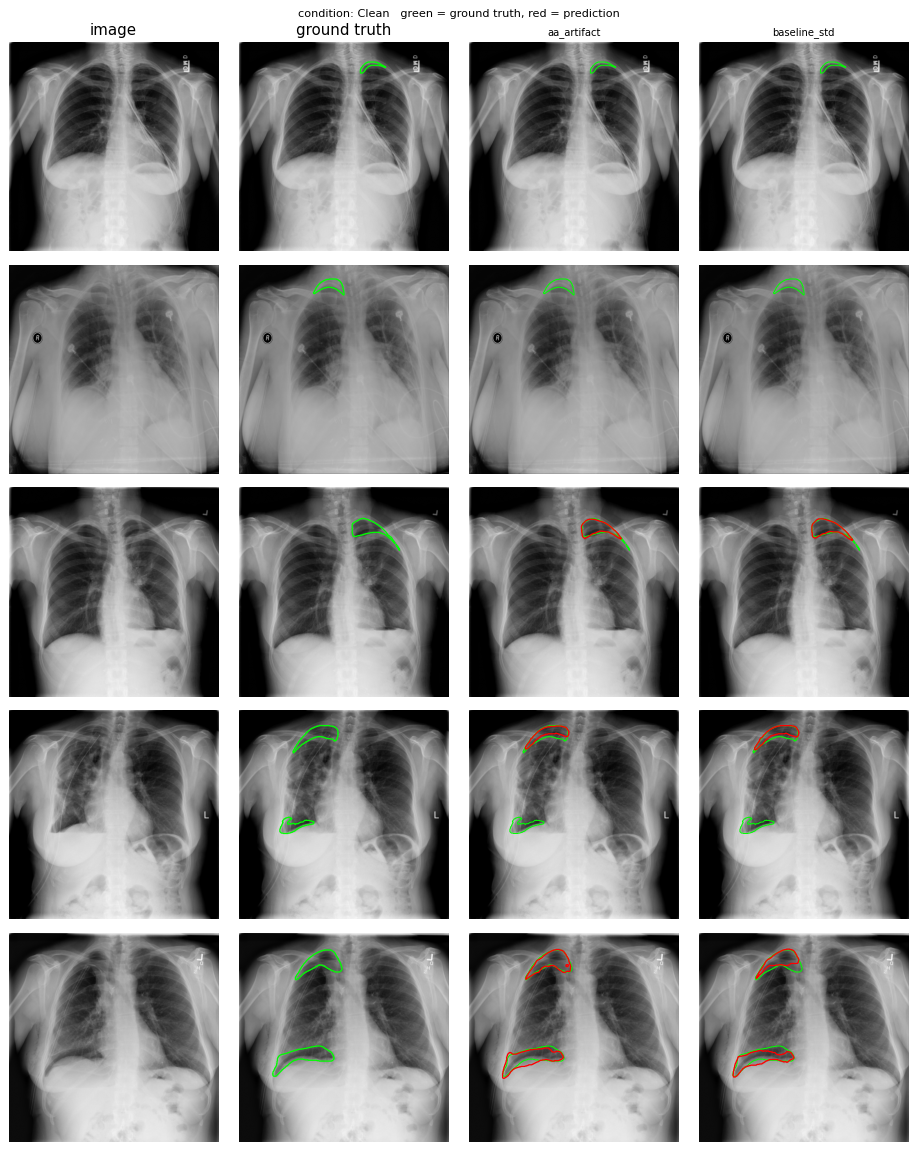

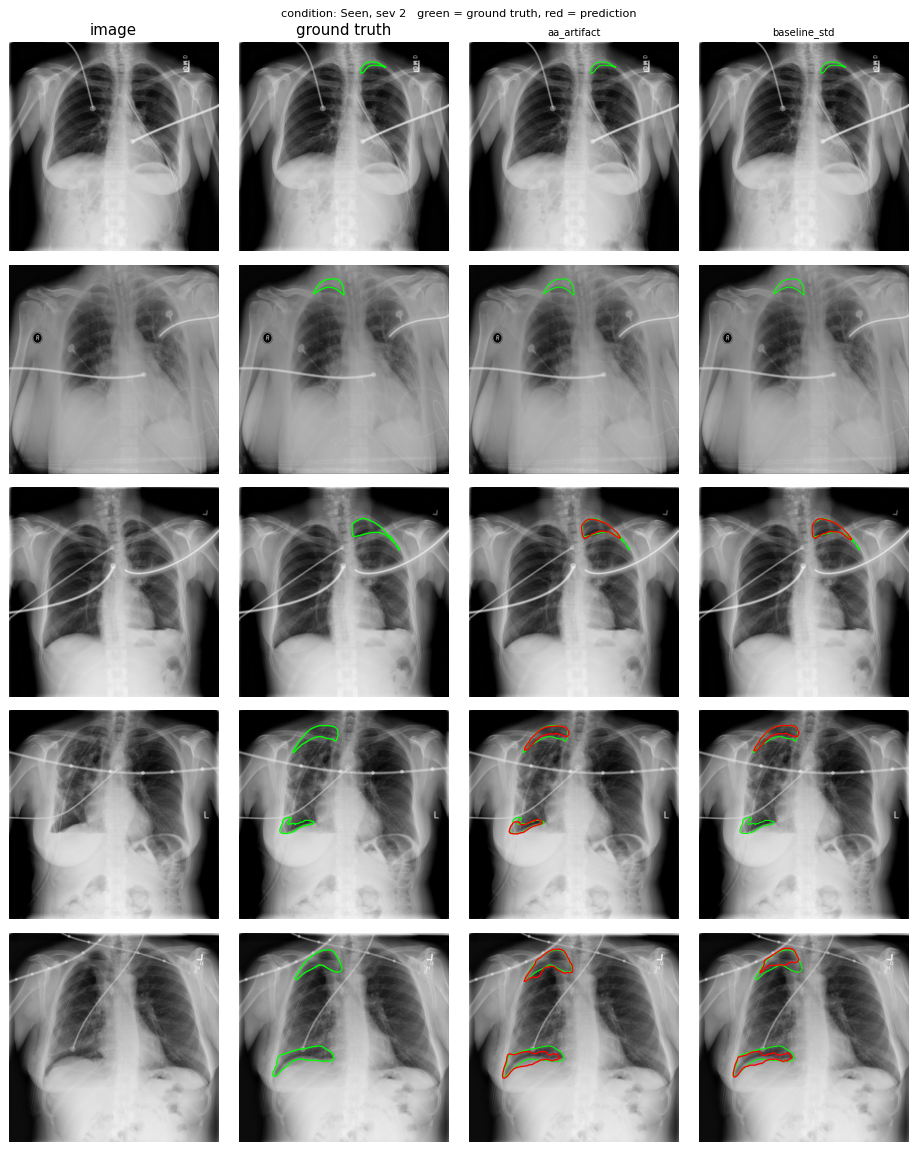

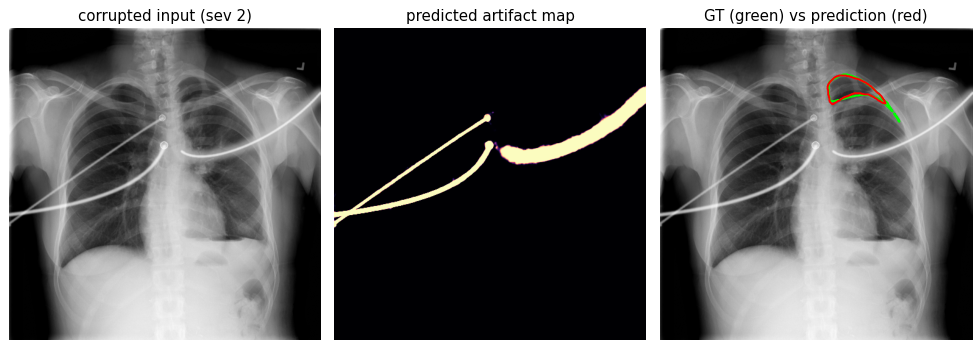

In [29]:
# ---- figures ----
R.plot_robustness(TEST_DIR, TRAINED, FIG_DIR / "robustness.png"); plt.show()
R.plot_curves(TEST_DIR, [n for n in (MAIN_BASELINE, "aa_std", MAIN_PROPOSED) if n in TRAINED], FIG_DIR / "roc_pr_curves.png"); plt.show()
R.plot_lesion_size(TEST_DIR, [n for n in (MAIN_BASELINE, "aa_std", MAIN_PROPOSED) if n in TRAINED], FIG_DIR / "lesion_size.png"); plt.show()
for cond in ("clean", "sev2"):
    kp = {n: KEEP_DATA[n][cond] for n in KEEP_DATA if cond in KEEP_DATA[n]}
    if kp:
        R.plot_qualitative(kp, gts_test[KEEP], {n: OPS[n] for n in kp}, FIG_DIR / f"qualitative_{cond}.png", cond); plt.show()
# artifact-head output on a corrupted test image (proposed model)
if MAIN_PROPOSED in KEEP_DATA and "sev2" in KEEP_DATA[MAIN_PROPOSED]:
    k = KEEP_DATA[MAIN_PROPOSED]["sev2"]
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
    ax[0].imshow(k["imgs"][2], cmap="gray"); ax[0].set_title("corrupted input (sev 2)"); ax[1].imshow(k["arts"][2], cmap="magma", vmin=0, vmax=1); ax[1].set_title("predicted artifact map")
    ax[2].imshow(k["imgs"][2], cmap="gray"); ax[2].contour(gts_test[KEEP[2]], [.5], colors="lime"); ax[2].contour(M.postprocess(k["probs"][2], **OPS[MAIN_PROPOSED]), [.5], colors="red")
    ax[2].set_title("GT (green) vs prediction (red)")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / "artifact_head_output.png", dpi=120); plt.show()

## 10. Export — deployment bundle for the Streamlit app + results package

In [30]:
# ---- deployment bundle: weights + config + tuned operating point + the code needed to load them (no Kaggle paths) ----
BUNDLE = WORK / "deployment_bundle"
if BUNDLE.exists(): shutil.rmtree(BUNDLE)
shutil.copytree(WORK / "src" / "aa_pneumo", BUNDLE / "aa_pneumo", ignore=shutil.ignore_patterns("__pycache__"))
export = {"aa_hybrid_unet": MAIN_PROPOSED, "baseline_unet": MAIN_BASELINE, "aa_hybrid_unet_std_aug": "aa_std"}
for folder, run_name in export.items():
    if run_name not in TRAINED: continue
    ck = E.load_ckpt(RUNS_DIR / run_name / "best.pt", "cpu"); d = BUNDLE / "models" / folder; d.mkdir(parents=True, exist_ok=True)
    cfg = dict(ck["model_cfg"]); cfg["pretrained"] = False
    torch.save({"model": ck["model"]}, d / "weights.pt")
    (d / "model_config.json").write_text(json.dumps(dict(kind=ck["kind"], model_cfg=cfg, img_size=IMG_SIZE, name=run_name, run=run_name,
                                                          best_epoch=int(ck["epoch"]) + 1, source_sha1=src_hash), indent=1))
    (d / "operating_point.json").write_text(json.dumps(OPS[run_name]))
    s = R.load_summaries(TEST_DIR, run_name, ["clean"]).get("clean", {})
    (d / "test_metrics_clean.json").write_text(json.dumps({k: v for k, v in s.items() if isinstance(v, (int, float))}, indent=1))
    m2, meta2, op2, _ = I.load_bundle(d, "cpu")        # prove that the bundle reloads and reproduces the checkpoint
    xx = torch.rand(1, 3, IMG_SIZE, IMG_SIZE); m1, _ = load_run_model(run_name)
    with torch.no_grad(): diff = float((m1.cpu()(xx)["seg"] - m2(xx)["seg"]).abs().max())
    assert diff < 1e-4, f"bundle mismatch for {run_name}: {diff}"
    print(f"bundle {folder:24s} <- {run_name}  ({(d / 'weights.pt').stat().st_size / 1e6:.0f} MB)  reload check max|diff| = {diff:.1e}")
(BUNDLE / "README.txt").write_text(
    "AA-HybridUNet deployment bundle (research prototype, NOT a clinical device).\n"
    "models/<name>/weights.pt + model_config.json + operating_point.json ; code in aa_pneumo/.\n"
    "Use in Python:  sys.path.insert(0, '<bundle>');  from aa_pneumo.infer import load_bundle, predict_image\n"
    "Streamlit: unzip next to app.py so that the folder structure is  app.py, aa_pneumo/, models/<name>/...\n")
shutil.make_archive(str(WORK / "deployment_bundle"), "zip", BUNDLE)
# ---- results package: tables, figures, histories, per-image results, operating points, configs (no weights) ----
PKG_RES = WORK / "results_package"
if PKG_RES.exists(): shutil.rmtree(PKG_RES)
shutil.copytree(RES_DIR, PKG_RES / "results", ignore=shutil.ignore_patterns("*_hist.npz"))
for n in TRAINED:
    d = PKG_RES / "runs" / n; d.mkdir(parents=True, exist_ok=True)
    for f in ("history.csv", "run_config.json", "done.json", "operating_point.json", "val_tuning_grid.csv", "efficiency.json"):
        if (RUNS_DIR / n / f).exists(): shutil.copy(RUNS_DIR / n / f, d / f)
shutil.copytree(WORK / "src", PKG_RES / "src", ignore=shutil.ignore_patterns("__pycache__"))
shutil.make_archive(str(WORK / "results_package"), "zip", PKG_RES)
print("\nzip files:", [f"{p.name} ({p.stat().st_size / 1e6:.0f} MB)" for p in WORK.glob("*.zip")])
try:
    from IPython.display import FileLink
    for z in ("deployment_bundle.zip", "results_package.zip"):
        display(FileLink(str((WORK / z).relative_to("/kaggle/working")) if ON_KAGGLE else str(WORK / z)))
except Exception:
    pass

bundle aa_hybrid_unet           <- aa_artifact  (81 MB)  reload check max|diff| = 0.0e+00
bundle baseline_unet            <- baseline_std  (78 MB)  reload check max|diff| = 0.0e+00

zip files: ['deployment_bundle.zip (148 MB)', 'results_package.zip (4 MB)']


/kaggle/working/aa_pneumo_experiment/deployment_bundle.zip

/kaggle/working/aa_pneumo_experiment/results_package.zip

In [31]:
# ---- final summary ----
print("=" * 100); print("DONE.  Total wall time this session: %.1f h" % ((time.time() - SESSION_T0) / 3600)); print("=" * 100)
if T1 is not None:
    print("\nPrimary comparison (clean test set):"); display(T1.T.iloc[:8])
print("\nUnfinished runs (resume them in the next session):", [n for n in RUN_NAMES if not (RUNS_DIR / n / "done.json").exists()] or "none")
print('''
LIMITATIONS to state in the paper
 * Synthetic artifacts are procedurally drawn; robustness on them is NOT clinical validation. The artifact head is supervised only on synthetic devices;
   real devices already present in the X-rays are unlabelled.
 * The PNG dataset has no patient identifier: only exact-duplicate images are kept apart across train/validation (and checked against test).
 * Metrics are computed at the reduced resolution; the original-resolution ceiling is printed in section 3.
 * Single seed, single split; confidence intervals are over test images (bootstrap), not over training runs.
 * Image-level ROC/PR use max pixel probability as the score; pixel-level specificity/accuracy are dominated by background.
 * Operating points (threshold, minimum areas) were tuned on the validation split only.
''')

DONE.  Total wall time this session: 3.8 h

Primary comparison (clean test set):


,baseline_std,aa_artifact
Dice (lesion imgs),"0.416 [0.374, 0.457]","0.400 [0.357, 0.440]"
Dice (all imgs),"0.861 [0.845, 0.877]","0.856 [0.840, 0.872]"
IoU (lesion imgs),"0.331 [0.295, 0.365]","0.318 [0.282, 0.352]"
Sensitivity,0.574,0.550
Precision,0.669,0.686
Specificity*,0.999,0.999
MCC,0.618,0.613
HD95 (px),67.35,74.95



Unfinished runs (resume them in the next session): none

LIMITATIONS to state in the paper
 * Synthetic artifacts are procedurally drawn; robustness on them is NOT clinical validation. The artifact head is supervised only on synthetic devices;
   real devices already present in the X-rays are unlabelled.
 * The PNG dataset has no patient identifier: only exact-duplicate images are kept apart across train/validation (and checked against test).
 * Metrics are computed at the reduced resolution; the original-resolution ceiling is printed in section 3.
 * Single seed, single split; confidence intervals are over test images (bootstrap), not over training runs.
 * Image-level ROC/PR use max pixel probability as the score; pixel-level specificity/accuracy are dominated by background.
 * Operating points (threshold, minimum areas) were tuned on the validation split only.

